# 1. Título
## Fiscalização Ambiental e Autos de Infração do IBAMA em 2026 (Janeiro a Outubro)
**DCC011: Introdução a Banco de Dados — 2026/2**

# 2. Membros (nome e número de matrícula)
* **Evandro Araújo Furlaneto Delgado** — Matrícula: 2025018830
* **Letícia Schmidt Tolentino Santos** — Matrícula: 2025014168
* **Victor Daniel Barbosa Thomé** — Matrícula: 2026303953
* **Vitória Medeiros Carrera de Oliveira** — Matrícula: 2019027245
* **Yuri Florentino Kosfeld** — Matrícula: 2022038503

# 3. Descrição dos dados (qual a URL? qual o domínio? como os dados foram processados?)

### 3.1 Identificação e Domínio dos Dados
* **Tema:** Fiscalização Ambiental Federal e Autos de Infração do IBAMA em 2026.
* **Conjunto de Dados:** *Fiscalização – Auto de Infração* (Instituto Brasileiro do Meio Ambiente e dos Recursos Naturais Renováveis – IBAMA).
* **Fonte / URL:** [dados.gov.br/dados/conjuntos-dados/fiscalizacao-auto-de-infracao](https://dados.gov.br/dados/conjuntos-dados/fiscalizacao-auto-de-infracao).
* **Arquivo Base:** `auto_infracao_2026.csv`, atualizado em 27/10/2026, com 13.648 linhas e 84 colunas sobre autos lavrados de janeiro a outubro de 2026 em todas as 27 UFs.
* **Domínio:** Registros de infrações e sanções administrativas ambientais aplicadas pelo órgão federal sobre desmatamento ilegal, comércio de fauna silvestre, pesca predatória, poluição industrial e descumprimento de embargos.

---

### 3.2 Dicionário dos Principais Atributos Originais
* `SEQ_AUTO_INFRACAO`: Identificador sequencial do auto no sistema legador.
* `DES_STATUS_FORMULARIO`: Situação do auto (Lavrado, Cancelado, Danificado, etc.).
* `NUM_AUTO_INFRACAO`: Código alfanumérico identificador único do Auto de Infração (emitido pelo sistema eletrônico AIe).
* `TIPO_AUTO`: Sanção proposta (Multa simples, Multa diária, Advertência).
* `VAL_AUTO_INFRACAO`: Valor pecuniário da multa indicada pelo agente fiscal (em Reais).
* `GRAVIDADE_INFRACAO`: Gravidade da infração constatada (Baixa, Média, Grave).
* `DES_AUTO_INFRACAO`: Descrição circunstanciada do fato infracional.
* `FORMA_ENTREGA`: Meio empregado para dar ciência da autuação (Pessoalmente, Notificação, Edital, etc.).
* `DES_LOCAL_INFRACAO`: Descrição textual do local físico da ocorrência.
* `DS_BIOMAS_ATINGIDOS`: Bioma ou biomas afetados pela conduta infracional.
* `UNID_CONTROLE`: Unidade administrativa de fiscalização responsável pelo auto.
* `DAT_HORA_AUTO_INFRACAO`: Data e horário da lavratura do formulário de autuação.
* `COD_MUNICIPIO`: Código IBGE do município da infração.
* `MUNICIPIO`: Nome do município da infração.
* `UF`: Sigla da Unidade Federativa.
* `COD_INFRACAO`: Código tipificador legal da infração.
* `DES_INFRACAO`: Descrição jurídica da conduta tipificada.
* `TIPO_INFRACAO`: Classificação macro da conduta (Flora, Fauna, Pesca, Controle Ambiental, etc.).
* `NOME_INFRATOR`: Nome ou razão social da pessoa autuada.
* `CPF_CNPJ_INFRATOR`: Documento CPF ou CNPJ do infrator autuado.
* `TP_PESSOA_INFRATOR`: Tipo de personalidade jurídica (PF - Pessoa Física, PJ - Pessoa Jurídica).
* `NUM_LATITUDE_AUTO` / `NUM_LONGITUDE_AUTO`: Coordenadas geográficas decimais.
* `ORDEM_FISCALIZACAO`: Código alfanumérico da ordem de fiscalização institucional de campo.
* `UNID_ORDENADORA`: Unidade administrativa expedidora da ordem fiscal.
* `OPERACAO_SOL_RECURSO`: Nome da operação especial de fiscalização planejada em campo.

---

### 3.3 Modelo Relacional Normalizado Proposto
Em total alinhamento com a proposta oficial submetida (`TP2_IBD_PROPOSTA.md`), a base desnormalizada de 84 atributos foi decomposta em **5 tipos de entidade** e **1 relação associativa muitos-para-muitos (M:N)**:

1. **`INFRATOR` (9.858 instâncias):**
   * PK: `id_infrator` (chave substituta inteira). Cada infrator corresponde a um CPF/CNPJ distinto (normalizado só com dígitos); quando o documento não foi informado, à combinação nome + tipo de pessoa.
   * Atributos: `nome_infrator`, `tipo_pessoa`, `cpf_cnpj`.
2. **`MUNICIPIO` (1.674 instâncias):**
   * PK: `cod_municipio` (código oficial IBGE).
   * Atributos: `nome_municipio`, `uf`.
3. **`ORDEM_FISCALIZACAO` (872 instâncias):**
   * PK: `codigo_ordem` (da coluna `ORDEM_FISCALIZACAO`).
   * Atributos: `unidade_ordenadora`, `nome_operacao` (da coluna `OPERACAO_SOL_RECURSO`).
4. **`TIPO_INFRACAO` (23 instâncias):**
   * PK: `id_tipo` (chave substituta inteira identificando cada enquadramento).
   * Atributos: `cod_infracao`, `descricao_infracao`, `tipo_infracao`.
5. **`AUTO_INFRACAO` (13.619 instâncias):**
   * PK: `num_auto_infracao` (código alfanumérico do auto).
   * Atributos: `data_hora`, `valor_multa`, `tipo_auto`, `descricao_fato`, `forma_entrega`, `local`, `bioma`, `unidade_controle`, `latitude`, `longitude`.
   * Chaves Estrangeiras: `id_infrator` (FK $\rightarrow$ Infrator), `cod_municipio` (FK $\rightarrow$ Municipio), `id_tipo` (FK $\rightarrow$ Tipo_Infracao), `codigo_ordem` (FK $\rightarrow$ Ordem_Fiscalizacao).
6. **`AUTUADO_EM` (10.172 instâncias - Relacionamento M:N):**
   * Chave Composta: (`id_infrator`, `codigo_ordem`).
   * Modela em quais ordens e missões de fiscalização cada infrator foi autuado, capturando casos em que uma ordem autua múltiplos agentes e agentes são alvos de múltiplas ordens ao longo do ano.

---

### 3.4 Pré-processamento e Carga dos Dados no SQLite
O script a seguir implementa a ingestão autônoma:
* Verifica a presença de `auto_infracao_csv/auto_infracao_2026.csv` ou descompacta `auto_infracao_2026.csv` a partir do zip `auto_infracao_csv.zip`.
* Remove as linhas repetidas de um mesmo auto (29 linhas): o arquivo traz alguns autos em mais de uma versão (ex.: Lavrado e Cancelado). Mantém-se uma linha por `NUM_AUTO_INFRACAO`, priorizando a versão com status *Lavrado*, e todas as tabelas são povoadas a partir dessa base deduplicada.
* Padroniza o `CPF_CNPJ_INFRATOR` mantendo apenas os dígitos, pois o mesmo documento aparecia com e sem pontuação (ex.: `00.058.722/0001-05` e `00058722000105`), o que duplicava infratores.
* Converte números no formato brasileiro com vírgula para `REAL`.
* Executa o DDL e povoa as tabelas normalizadas em SQLite (`auto_infracao.db`).
* Povoa `Autuado_Em` por último, a partir dos autos já carregados (`SELECT DISTINCT id_infrator, codigo_ordem FROM Auto_Infracao`), garantindo que todo par infrator–ordem corresponda a pelo menos um auto.

In [1]:
import os
import zipfile
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import geobr
import geopandas as gpd


In [2]:
# Funções utilitárias de acesso ao SQLite
def fetch(query, conn, formatted=True):
    cur = conn.cursor()
    cur.execute(query)
    rs = cur.fetchall()
    columns = [desc[0] for desc in cur.description]
    cur.close()
    return pd.DataFrame(rs, columns=columns) if formatted else rs

def show_tables(conn):
    return [x[0] for x in fetch('SELECT tbl_name FROM sqlite_master WHERE type="table"', conn, False)]

def shape(table, conn):
    nrows = fetch(f'SELECT COUNT(*) FROM {table}', conn, False)[0][0]
    ncols = fetch(f'SELECT COUNT(*) FROM pragma_table_info("{table}")', conn, False)[0][0]
    return (nrows, ncols)

print("Bibliotecas e funções auxiliares carregadas com sucesso.")

Bibliotecas e funções auxiliares carregadas com sucesso.


In [3]:
# 1. Localização e Descompactação dos Dados
csv_candidates = [
    os.path.join('auto_infracao_csv', 'auto_infracao_2026.csv'),
    'auto_infracao_2026.csv'
]

csv_file = None
for path in csv_candidates:
    if os.path.exists(path):
        csv_file = path
        break

if not csv_file:
    zip_path = 'auto_infracao_csv.zip'
    if os.path.exists(zip_path):
        print(f"Descompactando auto_infracao_2026.csv a partir de {zip_path}...")
        extract_dir = 'auto_infracao_csv'
        os.makedirs(extract_dir, exist_ok=True)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            target_file = None
            for member in zip_ref.namelist():
                if member.endswith('auto_infracao_2026.csv'):
                    target_file = member
                    break
            if target_file:
                zip_ref.extract(target_file, extract_dir)
                csv_file = os.path.join(extract_dir, os.path.basename(target_file))
            else:
                raise FileNotFoundError("auto_infracao_2026.csv não encontrado no arquivo zip.")
    else:
        raise FileNotFoundError("Base de dados não encontrada (verifique auto_infracao_csv/ ou auto_infracao_csv.zip).")

print(f"Carregando dados a partir de: {csv_file}")
# CPF/CNPJ lido como texto para não perder zeros à esquerda
df_raw = pd.read_csv(csv_file, sep=';', encoding='utf-8', low_memory=False,
                     dtype={'CPF_CNPJ_INFRATOR': str})
print(f"Registros brutos lidos: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.")

Carregando dados a partir de: auto_infracao_csv/auto_infracao_2026.csv


Registros brutos lidos: 13648 linhas e 84 colunas.


In [4]:
# 2. Limpeza prévia

# Correção 2 - Autos repetidos: o mesmo NUM_AUTO_INFRACAO aparece em mais de uma linha,
# às vezes com uma versão Cancelada/Excluída. Mantemos uma linha por auto, priorizando
# a versão 'Lavrado'. Todas as tabelas são povoadas a partir desta base deduplicada,
# para que nenhuma entidade guarde dados vindos de versões descartadas.
prioridade_status = df_raw['DES_STATUS_FORMULARIO'].map({'Lavrado': 0}).fillna(1)
df_base = (df_raw.assign(_prioridade=prioridade_status)
                 .sort_values(['NUM_AUTO_INFRACAO', '_prioridade'], kind='stable')
                 .drop_duplicates(subset=['NUM_AUTO_INFRACAO'], keep='first')
                 .drop(columns='_prioridade')
                 .reset_index(drop=True))
print(f"Linhas repetidas de autos removidas: {len(df_raw) - len(df_base)} "
      f"({len(df_base)} autos únicos).")

# Correção 1 - CPF/CNPJ com e sem pontuação: o mesmo documento aparecia como
# '00.058.722/0001-05' e '00058722000105', gerando dois infratores. Mantemos só os dígitos.
df_base['CPF_CNPJ_INFRATOR'] = df_base['CPF_CNPJ_INFRATOR'].str.replace(r'\D', '', regex=True)
df_base.loc[df_base['CPF_CNPJ_INFRATOR'] == '', 'CPF_CNPJ_INFRATOR'] = None

Linhas repetidas de autos removidas: 29 (13619 autos únicos).


In [5]:
# 3. Conexão e Criação do Banco SQLite
db_name = 'auto_infracao.db'
if os.path.exists(db_name):
    os.remove(db_name)

conn = sqlite3.connect(db_name)
cur = conn.cursor()

# Otimizações de ingestão
cur.execute('PRAGMA foreign_keys = 0;')
cur.execute('PRAGMA synchronous = OFF;')
cur.execute('PRAGMA journal_mode = MEMORY;')

# DDL das 5 Tabelas e 1 Tabela Associativa M:N (TP2_IBD_PROPOSTA.md)
cur.executescript('''
CREATE TABLE Municipio (
    cod_municipio INTEGER PRIMARY KEY,
    nome_municipio TEXT NOT NULL,
    uf TEXT NOT NULL
);

CREATE TABLE Infrator (
    id_infrator INTEGER PRIMARY KEY AUTOINCREMENT,
    nome_infrator TEXT NOT NULL,
    tipo_pessoa TEXT,
    cpf_cnpj TEXT
);

CREATE TABLE Ordem_Fiscalizacao (
    codigo_ordem TEXT PRIMARY KEY,
    unidade_ordenadora TEXT NOT NULL,
    nome_operacao TEXT
);

CREATE TABLE Tipo_Infracao (
    id_tipo INTEGER PRIMARY KEY AUTOINCREMENT,
    cod_infracao INTEGER NOT NULL,
    descricao_infracao TEXT NOT NULL,
    tipo_infracao TEXT NOT NULL
);

CREATE TABLE Autuado_Em (
    id_infrator INTEGER NOT NULL,
    codigo_ordem TEXT NOT NULL,
    PRIMARY KEY (id_infrator, codigo_ordem),
    FOREIGN KEY (id_infrator) REFERENCES Infrator(id_infrator),
    FOREIGN KEY (codigo_ordem) REFERENCES Ordem_Fiscalizacao(codigo_ordem)
);

CREATE TABLE Auto_Infracao (
    num_auto_infracao TEXT PRIMARY KEY,
    data_hora TEXT NOT NULL,
    valor_multa REAL,
    tipo_auto TEXT,
    descricao_fato TEXT,
    forma_entrega TEXT,
    local TEXT,
    bioma TEXT,
    unidade_controle TEXT,
    latitude REAL,
    longitude REAL,
    id_infrator INTEGER NOT NULL,
    cod_municipio INTEGER NOT NULL,
    id_tipo INTEGER NOT NULL,
    codigo_ordem TEXT,
    FOREIGN KEY (id_infrator) REFERENCES Infrator(id_infrator),
    FOREIGN KEY (cod_municipio) REFERENCES Municipio(cod_municipio),
    FOREIGN KEY (id_tipo) REFERENCES Tipo_Infracao(id_tipo),
    FOREIGN KEY (codigo_ordem) REFERENCES Ordem_Fiscalizacao(codigo_ordem)
);
''')
cur.close()
conn.commit()

In [6]:
# 4. Povoamento das Entidades Normalizadas

# A. Municipio
mun = df_base[['COD_MUNICIPIO', 'MUNICIPIO', 'UF']].dropna(subset=['COD_MUNICIPIO']).drop_duplicates(subset=['COD_MUNICIPIO']).copy()
mun.columns = ['cod_municipio', 'nome_municipio', 'uf']
mun['cod_municipio'] = mun['cod_municipio'].astype(int)
mun.to_sql('Municipio', conn, if_exists='append', index=False)

# B. Infrator - identificado pelo CPF/CNPJ (só dígitos). Quando o documento está vazio,
# o infrator é identificado pela combinação nome + tipo de pessoa.
df_base['chave_infrator'] = df_base['CPF_CNPJ_INFRATOR'].where(
    df_base['CPF_CNPJ_INFRATOR'].notna(),
    'SEM_DOC|' + df_base['NOME_INFRATOR'].astype(str) + '|' + df_base['TP_PESSOA_INFRATOR'].fillna('').astype(str)
)
# Para documentos registrados com nomes diferentes, fica o nome mais frequente
inf = (df_base.groupby('chave_infrator', sort=False)
              .agg(nome_infrator=('NOME_INFRATOR', lambda s: s.mode().iloc[0]),
                   tipo_pessoa=('TP_PESSOA_INFRATOR', 'first'),
                   cpf_cnpj=('CPF_CNPJ_INFRATOR', 'first'))
              .reset_index())
inf['id_infrator'] = inf.index + 1
inf[['id_infrator', 'nome_infrator', 'tipo_pessoa', 'cpf_cnpj']].to_sql('Infrator', conn, if_exists='append', index=False)

# C. Ordem_Fiscalizacao
ordem = df_base[['ORDEM_FISCALIZACAO', 'UNID_ORDENADORA', 'OPERACAO_SOL_RECURSO']].dropna(subset=['ORDEM_FISCALIZACAO']).drop_duplicates(subset=['ORDEM_FISCALIZACAO']).copy()
ordem.columns = ['codigo_ordem', 'unidade_ordenadora', 'nome_operacao']
ordem.to_sql('Ordem_Fiscalizacao', conn, if_exists='append', index=False)

# D. Tipo_Infracao
tipo = df_base[['COD_INFRACAO', 'DES_INFRACAO', 'TIPO_INFRACAO']].drop_duplicates().copy().reset_index(drop=True)
tipo['id_tipo'] = tipo.index + 1
tipo.columns = ['cod_infracao', 'descricao_infracao', 'tipo_infracao', 'id_tipo']
tipo['cod_infracao'] = tipo['cod_infracao'].astype(int)
tipo[['id_tipo', 'cod_infracao', 'descricao_infracao', 'tipo_infracao']].to_sql('Tipo_Infracao', conn, if_exists='append', index=False)

# E. Auto_Infracao (uma linha por auto, já deduplicada na etapa 2)
df_auto = (df_base.merge(inf[['chave_infrator', 'id_infrator']], on='chave_infrator', how='left')
                  .merge(tipo, left_on=['COD_INFRACAO', 'DES_INFRACAO', 'TIPO_INFRACAO'],
                         right_on=['cod_infracao', 'descricao_infracao', 'tipo_infracao'], how='left'))

def clean_float(val):
    if pd.isna(val):
        return None
    val_str = str(val).replace('.', '').replace(',', '.')
    try:
        return float(val_str)
    except:
        return None

df_auto['valor_multa'] = df_auto['VAL_AUTO_INFRACAO'].apply(clean_float)
df_auto['latitude'] = df_auto['NUM_LATITUDE_AUTO'].apply(clean_float)
df_auto['longitude'] = df_auto['NUM_LONGITUDE_AUTO'].apply(clean_float)

auto = df_auto[['NUM_AUTO_INFRACAO', 'DAT_HORA_AUTO_INFRACAO', 'valor_multa', 'TIPO_AUTO', 'DES_AUTO_INFRACAO', 'FORMA_ENTREGA', 'DES_LOCAL_INFRACAO', 'DS_BIOMAS_ATINGIDOS', 'UNID_CONTROLE', 'latitude', 'longitude', 'id_infrator', 'COD_MUNICIPIO', 'id_tipo', 'ORDEM_FISCALIZACAO']].copy()
auto.columns = ['num_auto_infracao', 'data_hora', 'valor_multa', 'tipo_auto', 'descricao_fato', 'forma_entrega', 'local', 'bioma', 'unidade_controle', 'latitude', 'longitude', 'id_infrator', 'cod_municipio', 'id_tipo', 'codigo_ordem']
auto['cod_municipio'] = auto['cod_municipio'].astype(int)
auto.to_sql('Auto_Infracao', conn, if_exists='append', index=False)

# F. Autuado_Em (Relação M:N)
# Correção 3 - montada a partir dos autos já carregados, para que todo par
# infrator-ordem corresponda a pelo menos um auto existente.
cur = conn.cursor()
cur.execute('''
INSERT INTO Autuado_Em (id_infrator, codigo_ordem)
SELECT DISTINCT id_infrator, codigo_ordem
FROM Auto_Infracao
WHERE codigo_ordem IS NOT NULL;
''')
conn.commit()

# Reativação de garantias de integridade
cur.execute('PRAGMA foreign_keys = 1;')
cur.execute('PRAGMA synchronous = FULL;')
cur.execute('PRAGMA journal_mode = DELETE;')
cur.close()
print("Banco de dados 'auto_infracao.db' criado e populado conforme TP2_IBD_PROPOSTA.md!")

Banco de dados 'auto_infracao.db' criado e populado conforme TP2_IBD_PROPOSTA.md!


In [7]:
# Resumo das instâncias populadas em conformidade com TP2_IBD_PROPOSTA.md
tables = ['Infrator', 'Municipio', 'Ordem_Fiscalizacao', 'Tipo_Infracao', 'Autuado_Em', 'Auto_Infracao']
summary = []
for t in tables:
    nrows, ncols = shape(t, conn)
    summary.append({'Tabela': t, 'Colunas': ncols, 'Instâncias (Tuplas)': nrows})

df_summary = pd.DataFrame(summary)
print("=== RESUMO DO BANCO DE DADOS NORMALIZADO ===")
print(df_summary.to_string(index=False))
print(f"\nTotal Geral de Instâncias no Modelo: {df_summary['Instâncias (Tuplas)'].sum():,}")

=== RESUMO DO BANCO DE DADOS NORMALIZADO ===
            Tabela  Colunas  Instâncias (Tuplas)
          Infrator        4                 9858
         Municipio        3                 1674
Ordem_Fiscalizacao        3                  872
     Tipo_Infracao        4                   23
        Autuado_Em        2                10172
     Auto_Infracao       15                13619

Total Geral de Instâncias no Modelo: 36,218


# 4. Diagrama ER

Abaixo é apresentado o Diagrama Entidade-Relacionamento (ER) Conceitual projetado para a fiscalização ambiental do IBAMA em 2026, em estrita conformidade com a proposta aprovada ([TP2_IBD_PROPOSTA.md](TP2_IBD_PROPOSTA.md)):

### Componentes do Modelo Conceitual:
* **Entidades:**
  * **INFRATOR:** Pessoa física ou jurídica penalizada (`id_infrator` [PK], `nome_infrator`, `tipo_pessoa`, `cpf_cnpj`).
  * **MUNICIPIO:** Localidade geográfica (`cod_municipio` [PK], `nome_municipio`, `uf`).
  * **ORDEM_FISCALIZACAO:** Missão/ação fiscal de campo (`codigo_ordem` [PK], `unidade_ordenadora`, `nome_operacao`).
  * **TIPO_INFRACAO:** Enquadramento jurídico da conduta (`id_tipo` [PK], `cod_infracao`, `descricao_infracao`, `tipo_infracao`).
  * **AUTO_INFRACAO:** Documento/ato fiscalizatório (`num_auto_infracao` [PK], `data_hora`, `valor_multa`, `tipo_auto`, `descricao_fato`, `forma_entrega`, `local`, `bioma`, `unidade_controle`, `latitude`, `longitude`).

* **Relacionamentos e Cardinalidades:**
  * **`RECEBE` (INFRATOR, AUTO_INFRACAO):** 1:N (13.619 instâncias). Cada auto referencia o agente autuado e um infrator pode receber múltiplos autos.
  * **`OCORRE_EM` (MUNICIPIO, AUTO_INFRACAO):** 1:N (13.619 instâncias). Um município sedia múltiplos autos; cada auto ocorre em uma localidade.
  * **`ENQUADRA` (TIPO_INFRACAO, AUTO_INFRACAO):** 1:N (13.619 instâncias). Cada auto é enquadrado em uma tipificação legal.
  * **`DECORRE_DE` (ORDEM_FISCALIZACAO, AUTO_INFRACAO):** 1:N (13.466 instâncias). Autos originados a partir de ordens fiscalizatórias planejadas.
  * **`AUTUADO_EM` (INFRATOR, ORDEM_FISCALIZACAO):** **M:N (10.172 instâncias)**. Relacionamento muitos-para-muitos legítimo entre infratores e ordens de fiscalização de campo (uma missão autua dezenas de infratores, e agentes reincidentes são alvos de múltiplas ordens ao longo do ano).

```
+--------------------+        AUTUADO_EM (M:N)        +----------------------+
|      INFRATOR      | <============================> |  ORDEM_FISCALIZACAO  |
+--------------------+                                +----------------------+
         | (1)                                                   | (1)
       RECEBE                                                DECORRE_DE
         | (N)                                                   | (N)
   +----------------------------------------------------------------------+
   |                             AUTO_INFRACAO                            |
   +----------------------------------------------------------------------+
         | (N)                                                   | (N)
     OCORRE_EM                                                ENQUADRA
         | (1)                                                   | (1)
+--------------------+                                +----------------------+
|     MUNICIPIO      |                                |    TIPO_INFRACAO     |
+--------------------+                                +----------------------+
```

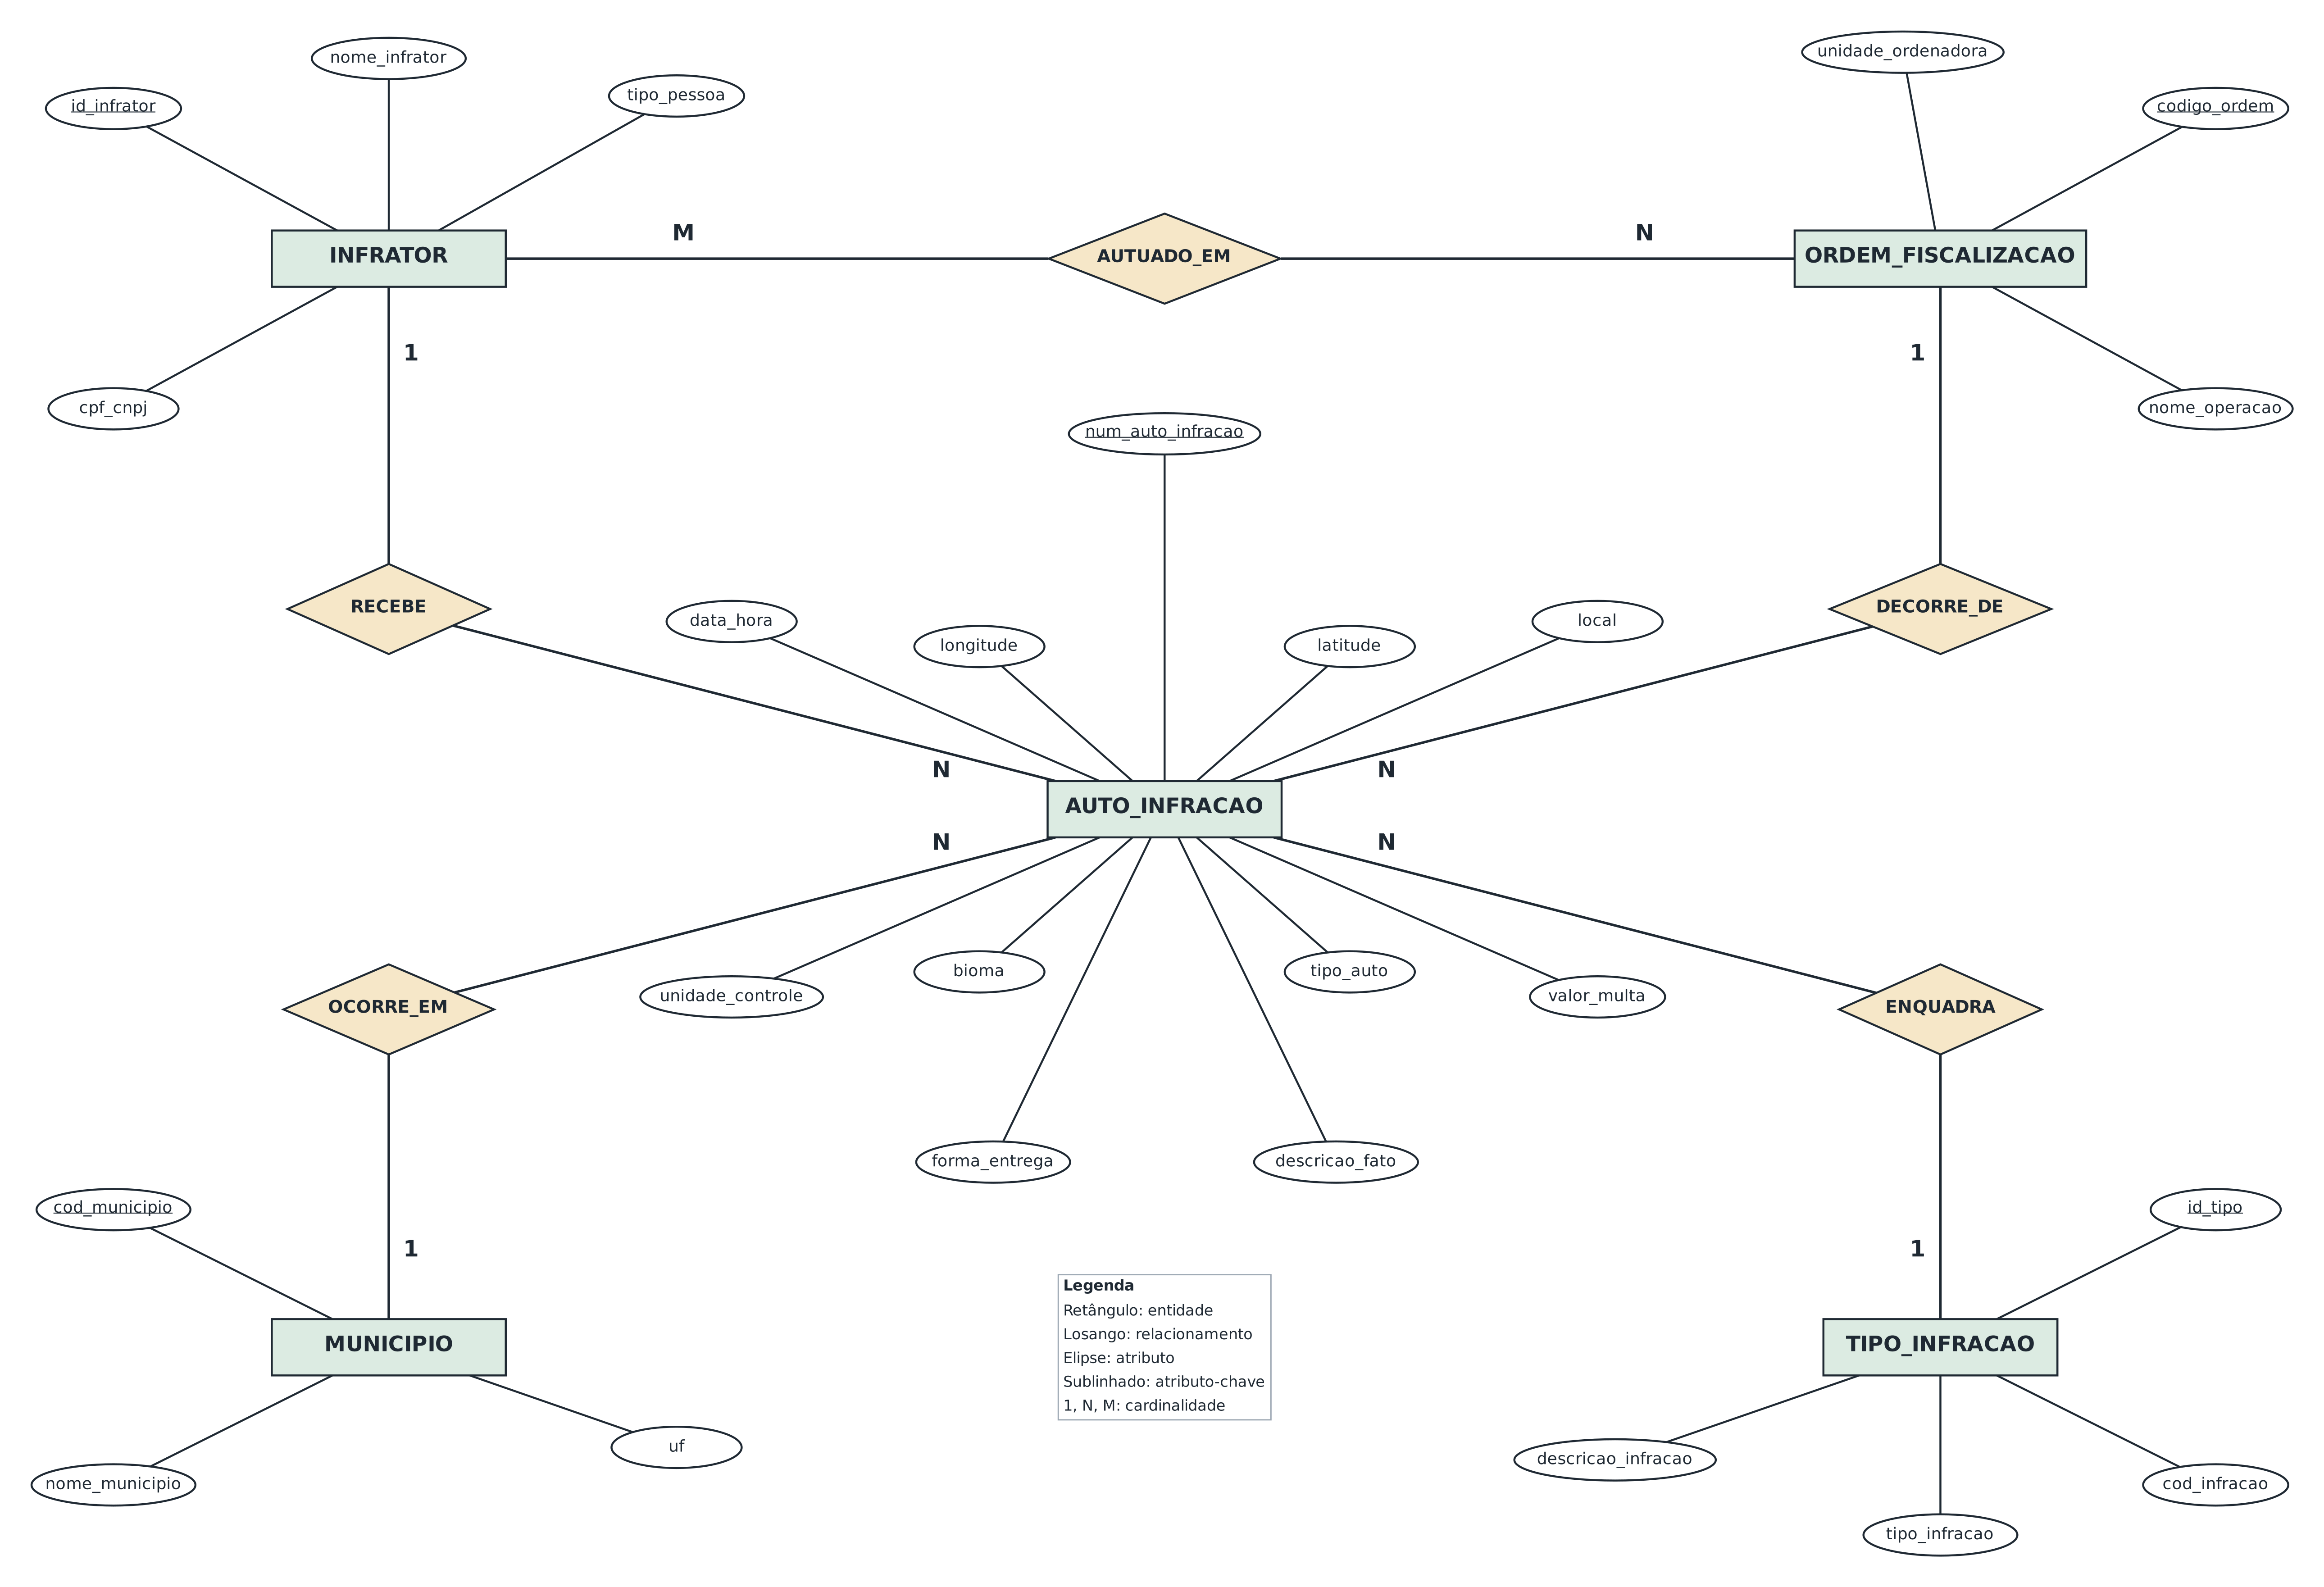

# 5. Diagrama relacional

Abaixo é apresentado o Esquema Lógico Relacional Normalizado resultante do mapeamento do modelo ER em Terceira Forma Normal (3FN):

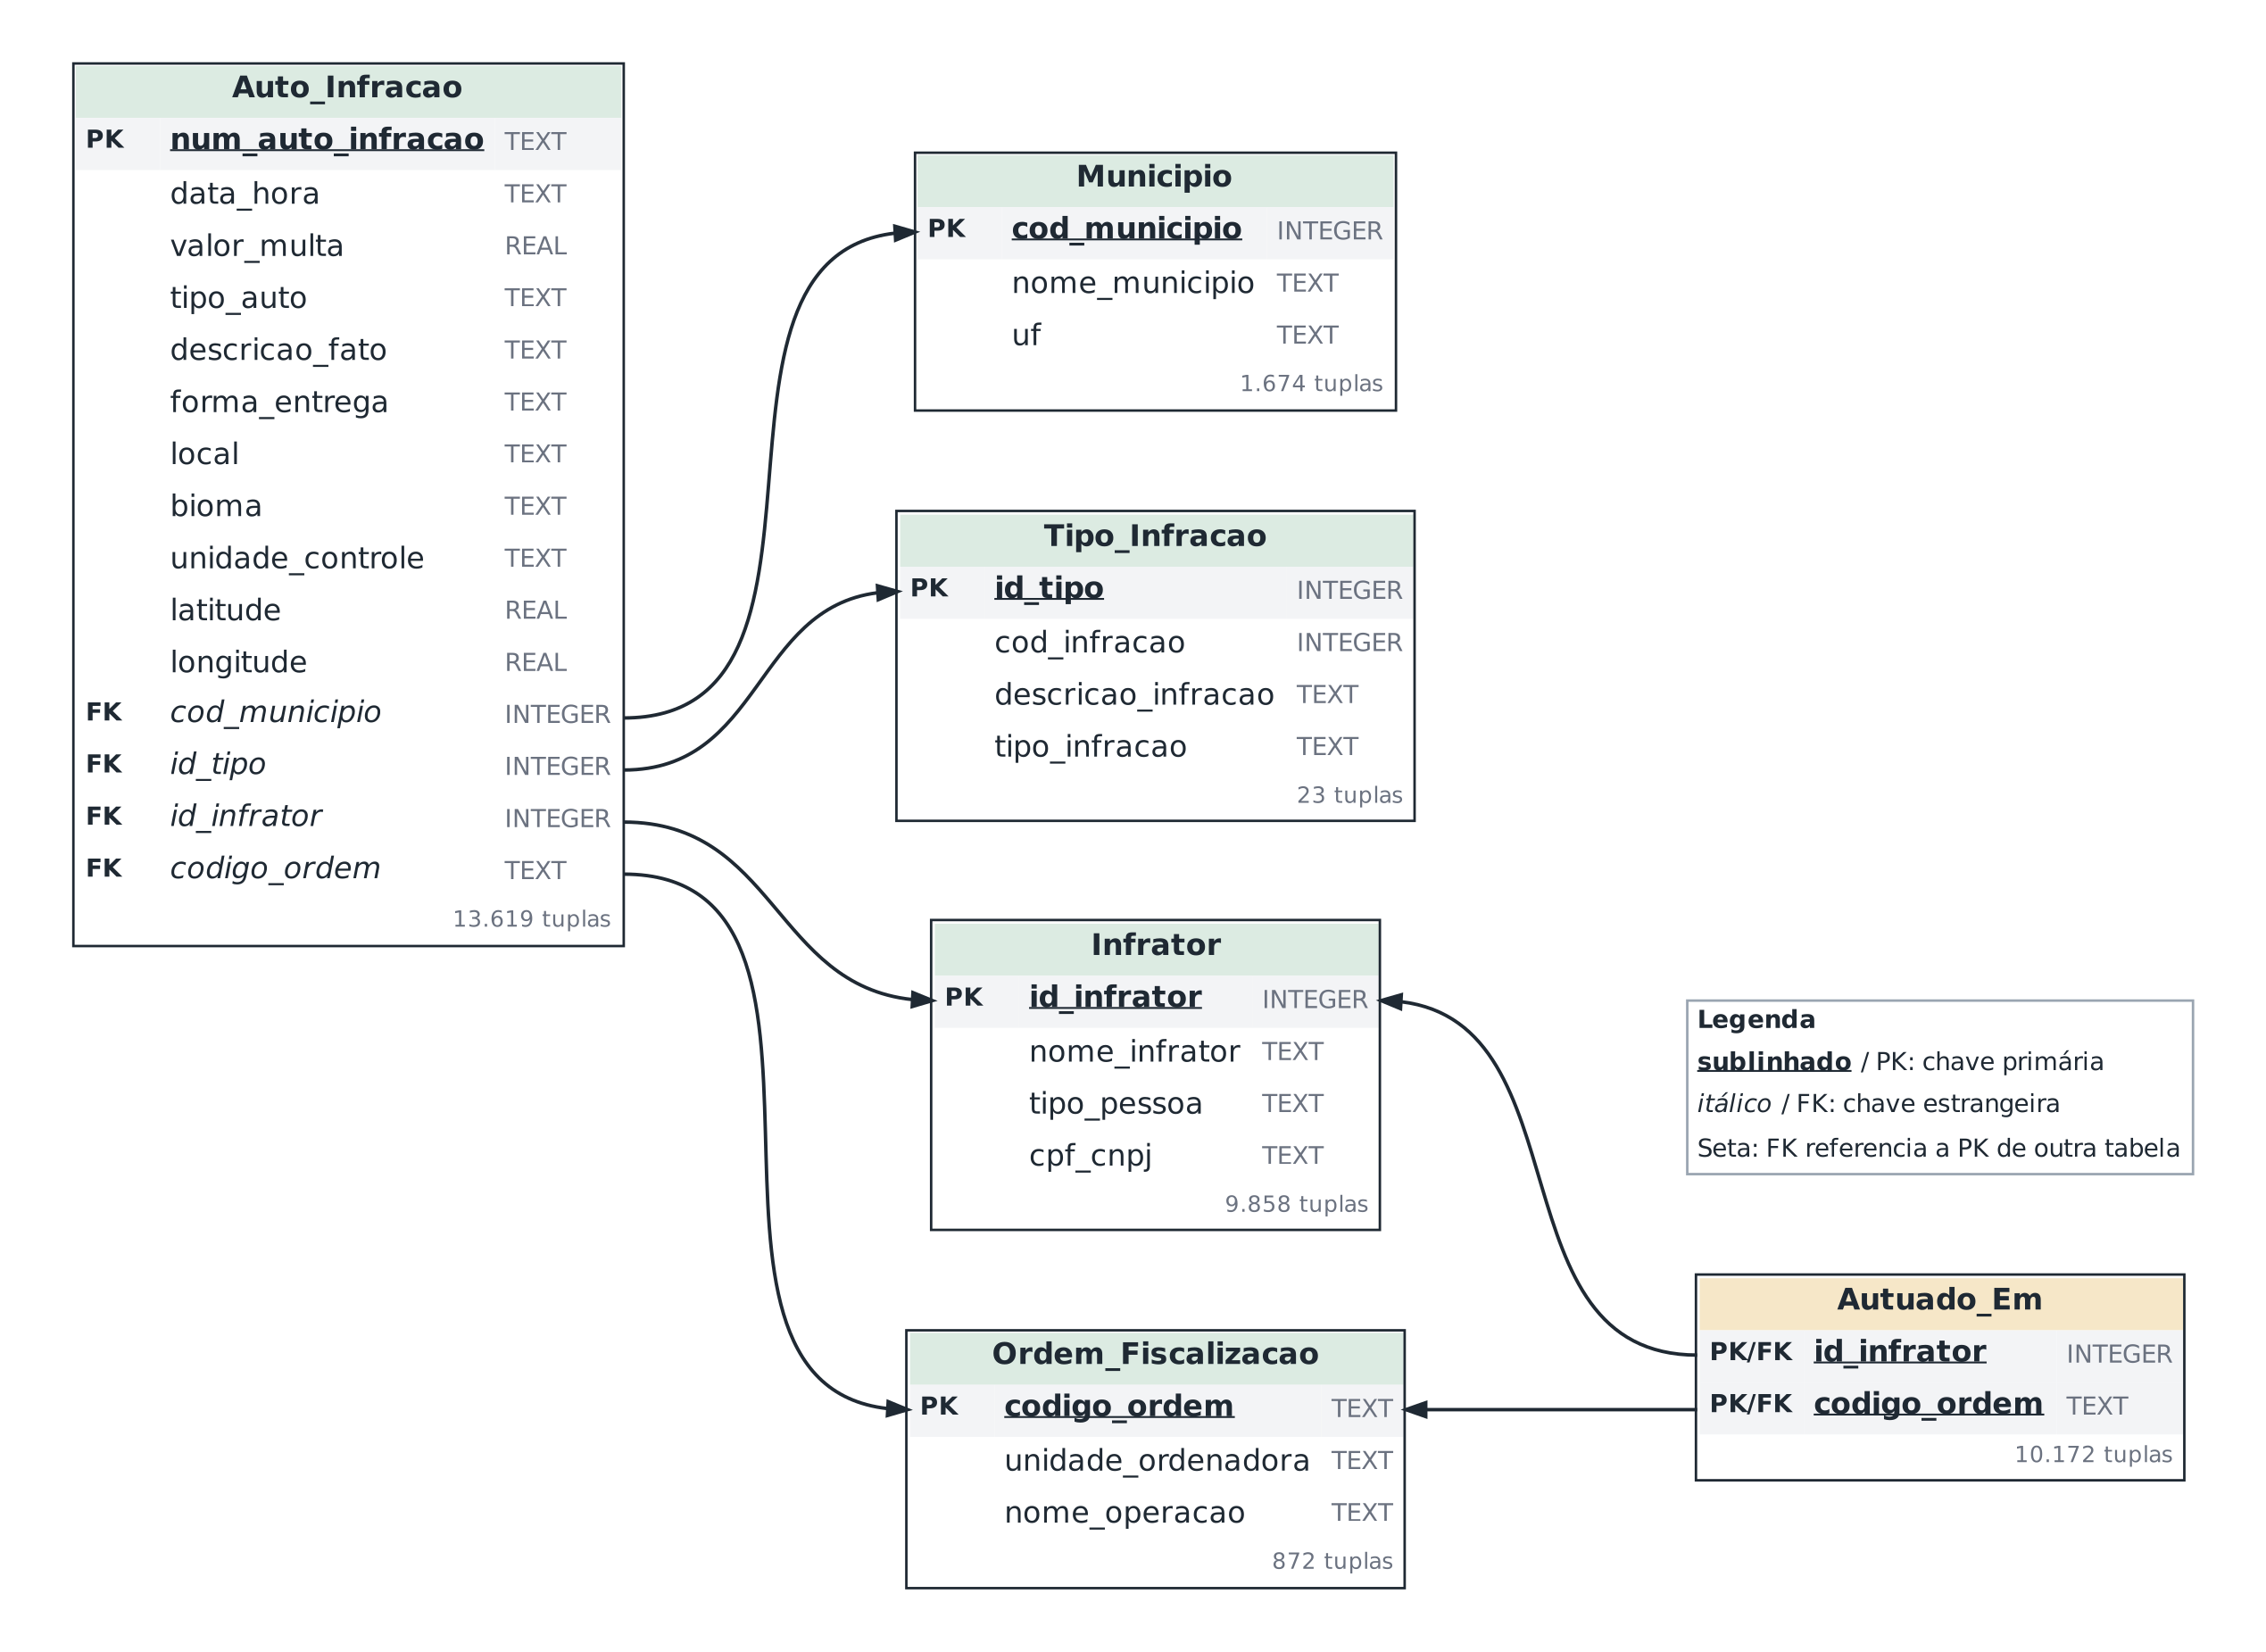

* **`Municipio`** (**`cod_municipio`**, `nome_municipio`, `uf`)
  * Chave Primária: `cod_municipio` (Código oficial IBGE).
---
* **`Infrator`** (**`id_infrator`**, `nome_infrator`, `tipo_pessoa`, `cpf_cnpj`)
  * Chave Primária: `id_infrator` (Chave surrogate inteira).
---
* **`Ordem_Fiscalizacao`** (**`codigo_ordem`**, `unidade_ordenadora`, `nome_operacao`)
  * Chave Primária: `codigo_ordem` (Identificador alfanumérico da ordem).
---
* **`Tipo_Infracao`** (**`id_tipo`**, `cod_infracao`, `descricao_infracao`, `tipo_infracao`)
  * Chave Primária: `id_tipo`.
---
* **`Autuado_Em`** (**`_id_infrator_`**, **`_codigo_ordem_`**)
  * Chave Primária Composta: (`id_infrator`, `codigo_ordem`).
  * Chave Estrangeira: `id_infrator` referencia `Infrator(id_infrator)`.
  * Chave Estrangeira: `codigo_ordem` referencia `Ordem_Fiscalizacao(codigo_ordem)`.
---
* **`Auto_Infracao`** (**`num_auto_infracao`**, `data_hora`, `valor_multa`, `tipo_auto`, `descricao_fato`, `forma_entrega`, `local`, `bioma`, `unidade_controle`, `latitude`, `longitude`, `_id_infrator_`, `_cod_municipio_`, `_id_tipo_`, `_codigo_ordem_`)
  * Chave Primária: `num_auto_infracao`.
  * Chave Estrangeira: `id_infrator` referencia `Infrator(id_infrator)`.
  * Chave Estrangeira: `cod_municipio` referencia `Municipio(cod_municipio)`.
  * Chave Estrangeira: `id_tipo` referencia `Tipo_Infracao(id_tipo)`.
  * Chave Estrangeira: `codigo_ordem` referencia `Ordem_Fiscalizacao(codigo_ordem)`.
---
Todas as restrições de domínio, unicidade e integridade referencial estão formalmente implementadas no SGBD SQLite.

# 6. Consultas

## 6.1 Duas consultas envolvendo seleção e projeção

### 6.1.1 Consulta 1
**Descrição:** Apresentar em ordem decrescente os biomas brasileiros pela quantidade de multas graves(modalidade "Multa simples" com valor igual ou superior a `R$1.000.000,00`) aplicadas (Investigação: Distribuição dos valores e concentração acima de R$ 1M).

In [8]:
query1 = """
SELECT bioma, COUNT(*)
FROM Auto_Infracao
WHERE valor_multa >= 1000000 AND tipo_auto = 'Multa simples'
GROUP BY bioma
ORDER BY COUNT(*) DESC
"""

fetch(query1, conn)

,bioma,COUNT(*)
0,Amazonia,595
1,Mata Atlantica,57
2,Cerrado,39
3,Pantanal,32
4,Costeiro e Marinho,32
5,Caatinga,26
6,Pampa,3


**Analisando os resultados:** A partir do resultado, é possível perceber que o bioma com maior incidência de infrações ambientais graves é a Amazônia, com 595 multas, tendo mais de 10x a quantidade de multas aplicadas do que a Mata Atlântica, que está em segundo lugar. Estes resultados podem ser explicados por uma série de motivos como garimpo ilegal (detalhado nos casos de mineração das **Consultas 3, 4 e 7**), grilagem, desmatamento (foco das auditorias florestais nas **Consultas 6, 7 e 9**), caça ilegal (categoria de fauna analisada nas **Consultas 7 e 9**), entre outras ações ilegais que ocorrem em grande quantidade na Amazônia, além do tamanho muito maior do bioma amazônico do que os outros biomas brasileiros. Na prática, esse filtro direto na tabela `Auto_Infracao` orienta o direcionamento estratégico de recursos de fiscalização e antecipa a concentração regional confirmada nos valores financeiros da **Consulta 10**.

### 6.1.2 Consulta 2
**Descrição:** Listar os infratores cadastrados como Pessoa Jurídica (PJ) que possuem número de CNPJ registrado, projetando o identificador do infrator, razão social e número fiscal de inscrição, ordenados alfabeticamente (Investigação: Perfil dos infratores PJ autuados).

In [9]:
query2 = """
SELECT id_infrator, nome_infrator, cpf_cnpj, tipo_pessoa
FROM Infrator
WHERE tipo_pessoa = 'PJ' AND cpf_cnpj IS NOT NULL
ORDER BY nome_infrator ASC
LIMIT 10;
"""

fetch(query2, conn)

,id_infrator,nome_infrator,cpf_cnpj,tipo_pessoa
0,4031,CASA DA MADEIRA LTDA,10418988000167,PJ
1,5798,POLE COFFEE EXPORTACAO E IMPORTACAO LTDA,07953619000160,PJ
2,8053,137 PESCADOS LTDA,61215914000164,PJ
3,393,2A COMERCIO DE GAS E BEBIDAS LTDA,15611034000190,PJ
4,1729,32850515 MARIANA AYALA RIBEIRO,32850515000177,PJ
5,2196,3E COMERCIAL LTDA,52584160000129,PJ
6,8019,3J AGRO E PARTICIPACÕES ESPECIAIS LTDA,35216667000453,PJ
7,248,3JS COMERCIO DE MADEIRAS EIRELI ME,42785991000105,PJ
8,6736,3M PARTICIPAÇÕES LTDA,00436476000170,PJ
9,4604,3N TRANSPORTES LTDA,22304126000192,PJ


**Analisando os resultados:** Por meio destes resultados é possível analisar o perfil e perceber padrões das entidades PJ que cometeram infrações ambientais; por exemplo, 5 das 10 primeiras empresas estão relacionadas ao agronegócio ou a madeireiras. Além de evidenciar o predomínio de atividades ligadas ao uso direto de recursos naturais e orientar ações de fiscalização preventiva por setor econômico, esse recorte cadastral da tabela `Infrator` serve de base para medir o impacto financeiro e a reincidência dessas empresas nas consultas de junção e agregação com `Auto_Infracao`.


## 6.2 Três consultas envolvendo junção de duas relações

### 6.2.1 Consulta 3
**Descrição:** Junção entre `Auto_Infracao` e `Infrator` para identificar quais agentes (pessoas físicas ou jurídicas) receberam o maior valor em multas lavradas em 2026, projetando nome do infrator, tipo de pessoa, valor total de multas, data e bioma afetado.

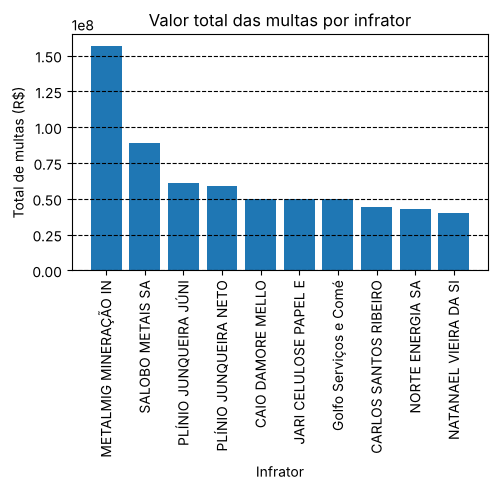

In [10]:
df_multa_individuo = fetch("""
SELECT nome_infrator, tipo_pessoa, SUM(valor_multa) as total_multa, bioma
FROM Auto_Infracao NATURAL JOIN Infrator
WHERE valor_multa IS NOT NULL
GROUP BY nome_infrator
ORDER BY total_multa DESC
""", conn)

plt.figure(figsize=(5, 5))

plt.bar(
    df_multa_individuo['nome_infrator'].head(10).str[:21],
    df_multa_individuo['total_multa'].head(10)
)
plt.xlabel('Infrator')
plt.ylabel('Total de multas (R$)')
plt.title('Valor total das multas por infrator')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=1, c = 'black')
plt.tight_layout()

plt.show()

In [11]:
fetch("""
SELECT nome_infrator, tipo_pessoa, SUM(valor_multa) as total_multa, bioma, SUBSTR(data_hora, 6, 2) AS mes
FROM Auto_Infracao NATURAL JOIN Infrator
WHERE valor_multa IS NOT NULL AND nome_infrator IN (
    'PLÍNIO JUNQUEIRA NETO',
    'PLÍNIO JUNQUEIRA JÚNIOR'
)
GROUP BY nome_infrator, mes
ORDER BY nome_infrator DESC
""", conn)

,nome_infrator,tipo_pessoa,total_multa,bioma,mes
0,PLÍNIO JUNQUEIRA NETO,PF,9030000.0,Pantanal,07
1,PLÍNIO JUNQUEIRA NETO,PF,50000000.0,Pantanal,08
2,PLÍNIO JUNQUEIRA JÚNIOR,PF,11045000.0,Pantanal,07
3,PLÍNIO JUNQUEIRA JÚNIOR,PF,50000000.0,Pantanal,08


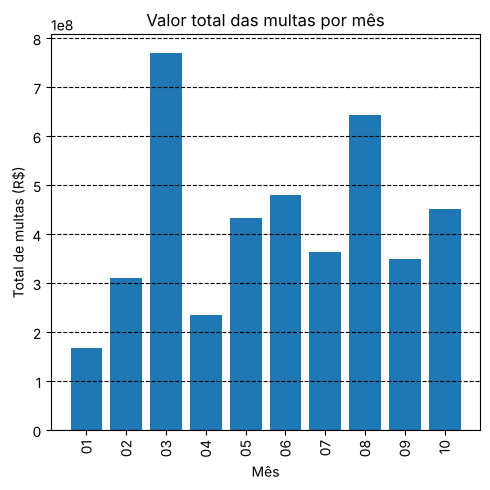

In [12]:

df_multa_mes = fetch("""
SELECT SUBSTR(DATA_HORA, 6, 2) AS mes, SUM(valor_multa) as total_multa, bioma
FROM Auto_Infracao NATURAL JOIN Infrator
WHERE valor_multa IS NOT NULL
GROUP BY mes
ORDER BY mes ASC
""", conn)

plt.figure(figsize=(5, 5))

plt.bar(
    df_multa_mes['mes'].head(10),
    df_multa_mes['total_multa'].head(10)
)
plt.xlabel('Mês')
plt.ylabel('Total de multas (R$)')
plt.title('Valor total das multas por mês')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=1, c = 'black')
plt.tight_layout()

plt.show()

**Analisando os resultados:** As pesquisas nos mostram que dentre os maiores infratores, 5 são de Pessoa Jurídica e 5 Pessoa Física, dentre os infratores de Pessoa Física, sobressaem-se Plínio Junqueira Junior e Plínio Junqueira Neto, que juntos somam **R\$ 120.075.000,00** em multas em apenas dois meses (Julho e Agosto de 2026).
Dentre os infratores de Pessoa Jurídica a empresa METALMIG MINERAÇÃO INDÚSTRIA E COMÉRCIO LTDA, se destaca por receber multas totalizando **R\$ 156.888.000,00**, quase o dobro do segundo maior infrator SALOBO METAIS SA com **R\$ 89.181.500,00** de multas ambientais em 2026.

### 6.2.2 Consulta 4
**Descrição:** Junção entre `Auto_Infracao` e `Municipio` para correlacionar autuações de grande impacto financeiro ($\ge$ R$ 2.000.000,00) com seus municípios e estados de ocorrência, além da distribuição financeira total das multas por município.

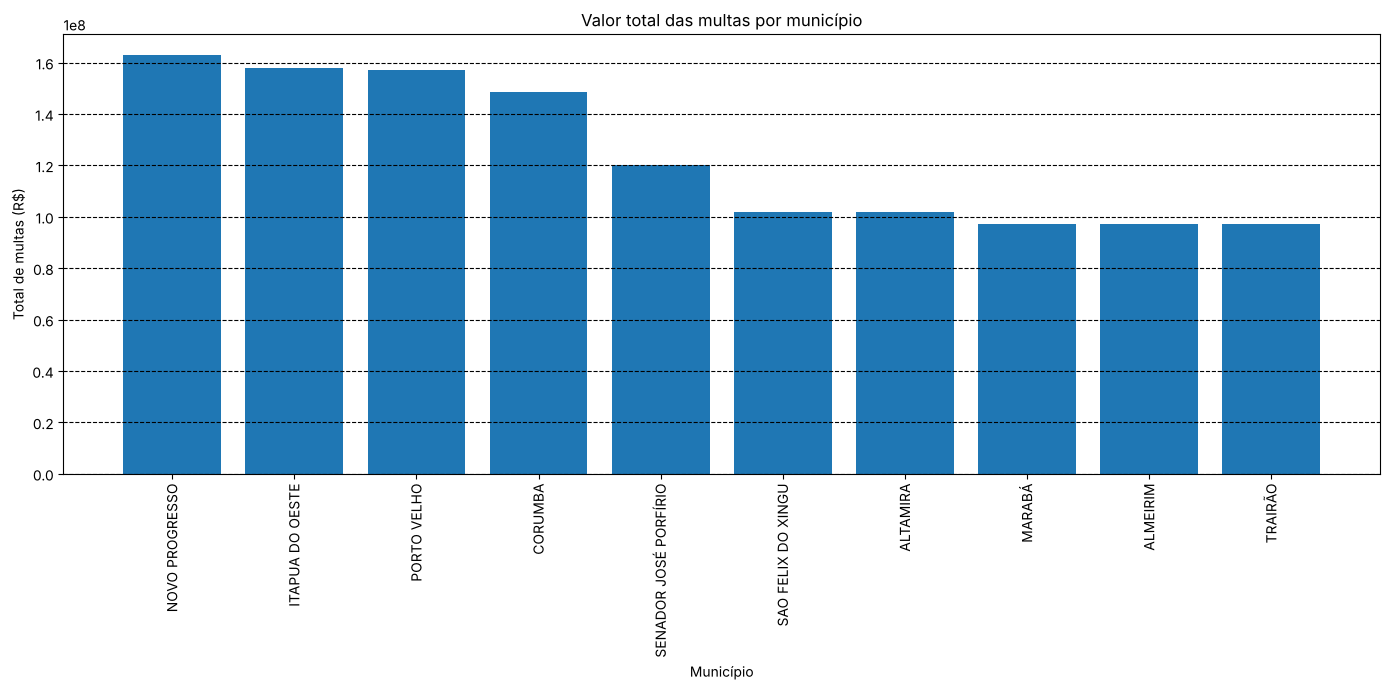

In [13]:
df_multa_municipio = fetch("""
SELECT nome_municipio, uf, bioma, SUM(valor_multa) AS total_multa
FROM Auto_Infracao NATURAL JOIN Municipio
WHERE valor_multa IS NOT NULL
GROUP BY nome_municipio, uf
ORDER BY total_multa DESC
""", conn)

plt.figure(figsize=(14, 7))

plt.bar(
    df_multa_municipio['nome_municipio'].head(10).str.upper(),
    df_multa_municipio['total_multa'].head(10)
)
plt.xlabel('Município')
plt.ylabel('Total de multas (R$)')
plt.title('Valor total das multas por município')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=1, c = 'black')
plt.tight_layout()

plt.show()

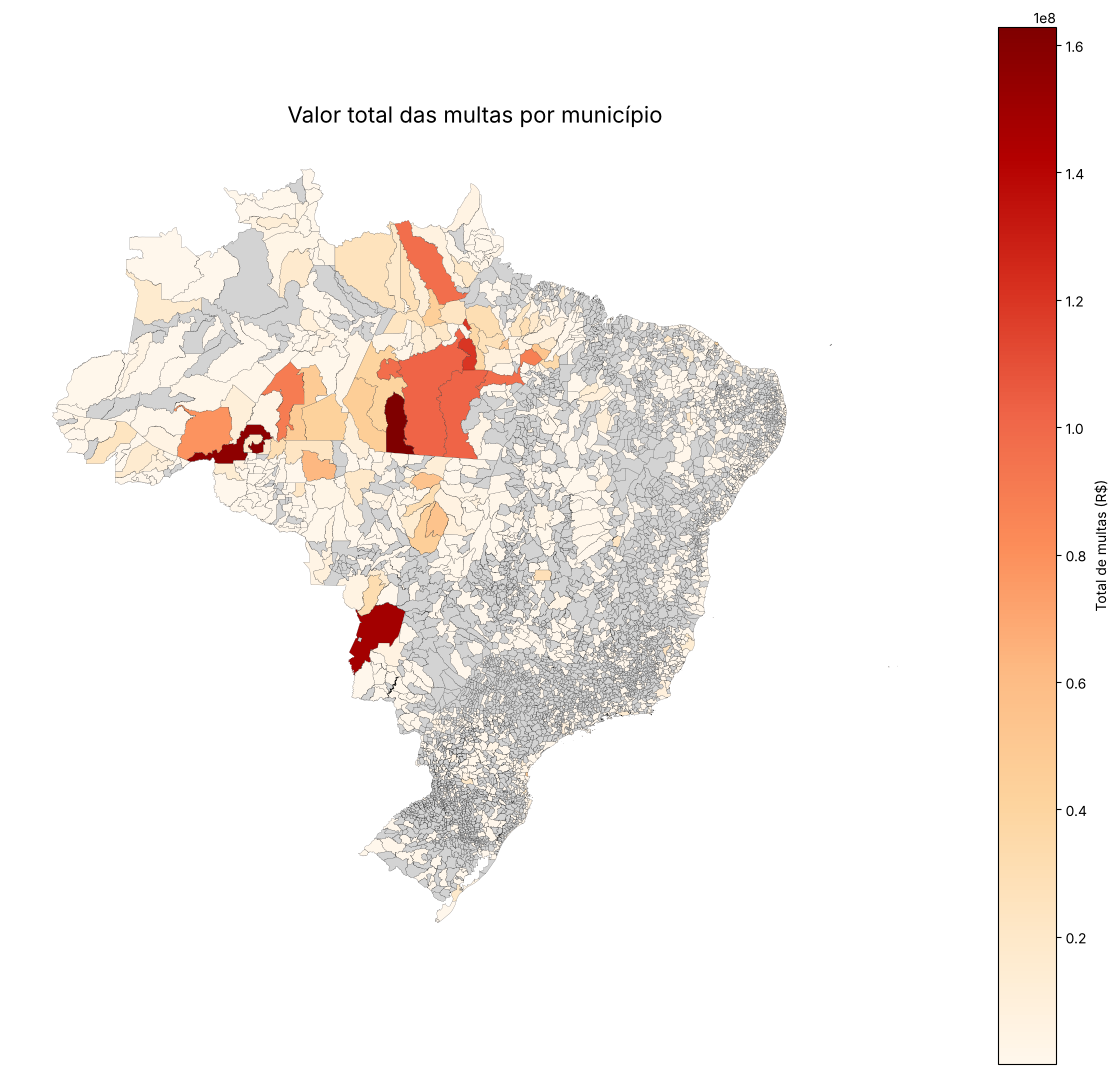

In [14]:
municipios = geobr.read_municipality(year = 2022)

df_multa_municipio['nome_norm'] = df_multa_municipio['nome_municipio'].str.upper().str.strip().str.replace('Á', 'A').str.replace('Ã', 'A').str.replace('Â', 'A').str.replace('É', 'E').str.replace('Ê', 'E').str.replace('Í', 'I').str.replace('Ó', 'O').str.replace('Ô', 'O').str.replace('Õ', 'O').str.replace('Ú', 'U').str.replace('Ç', 'C')
municipios['nome_norm'] = municipios['name_muni'].str.upper().str.strip().str.replace('Á', 'A').str.replace('Ã', 'A').str.replace('Â', 'A').str.replace('É', 'E').str.replace('Ê', 'E').str.replace('Í', 'I').str.replace('Ó', 'O').str.replace('Ô', 'O').str.replace('Õ', 'O').str.replace('Ú', 'U').str.replace('Ç', 'C')

mapa = municipios.merge(
    df_multa_municipio,
    left_on=['nome_norm', 'abbrev_state'],
    right_on=['nome_norm', 'uf'],
    how='left'
)

fig, ax = plt.subplots(1, 1, figsize=(15, 15))
mapa.plot(
    column='total_multa',
    cmap='OrRd',
    linewidth=0.1,
    edgecolor='black',
    legend=True,
    missing_kwds={
        'color': 'lightgrey',
        'label': 'Sem dados'
    },
    legend_kwds={
        'label': 'Total de multas (R$)',
        'orientation': 'vertical'
    },
    ax=ax
)
ax.set_title('Valor total das multas por município', fontsize=16)
ax.set_axis_off()

plt.show()

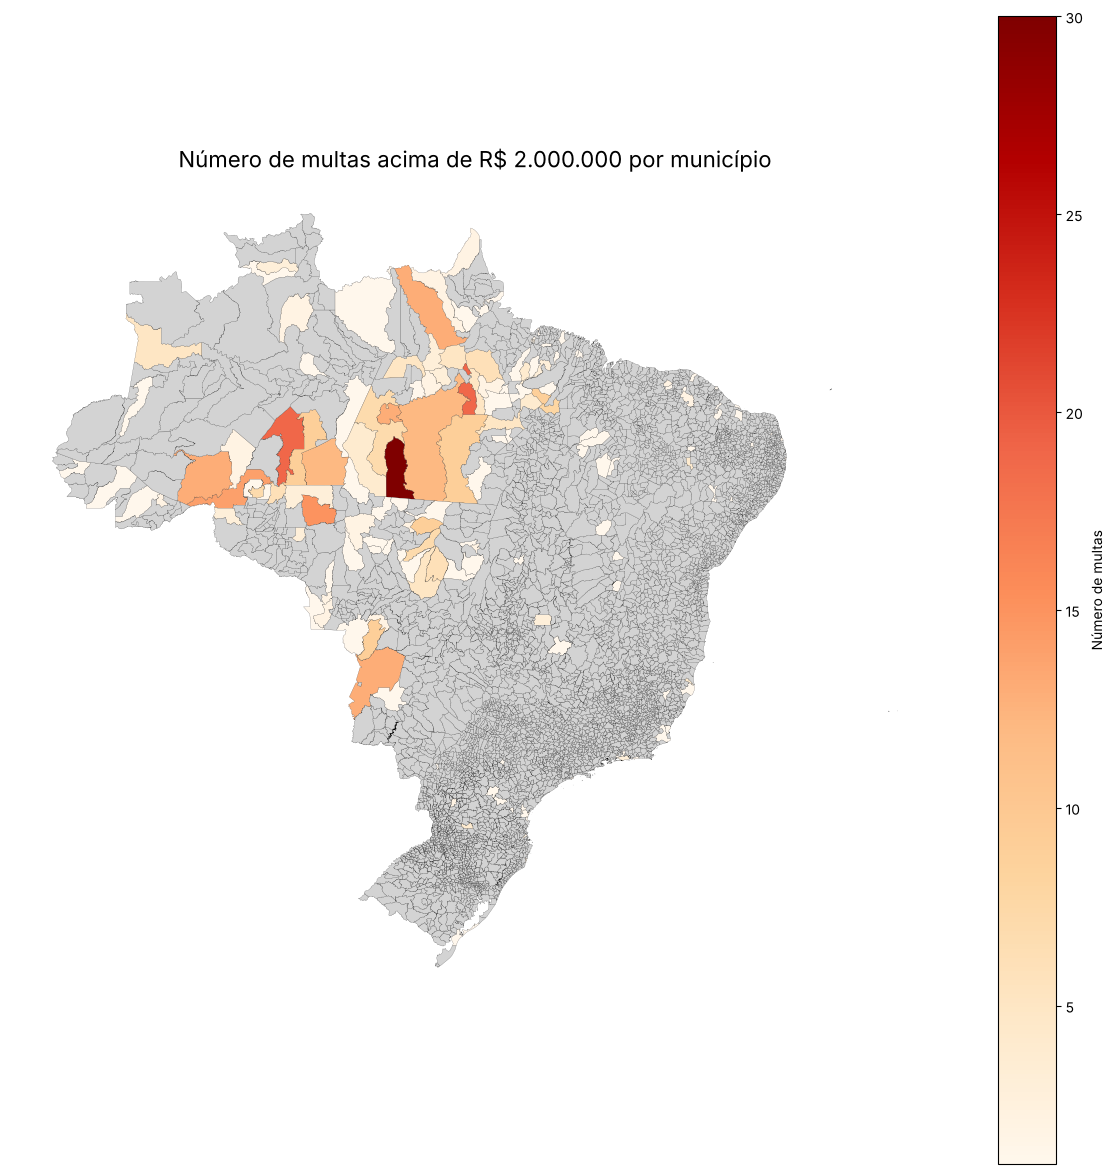

In [15]:
df_multa_municipio = fetch("""
SELECT nome_municipio, uf, bioma, valor_multa, COUNT(*) AS total_multa
FROM Auto_Infracao NATURAL JOIN Municipio
WHERE valor_multa >= 2000000
GROUP BY nome_municipio, uf
ORDER BY total_multa DESC
""", conn)

municipios = geobr.read_municipality(year = 2022)

df_multa_municipio['nome_norm'] = df_multa_municipio['nome_municipio'].str.upper().str.strip().str.replace('Á', 'A').str.replace('Ã', 'A').str.replace('Â', 'A').str.replace('É', 'E').str.replace('Ê', 'E').str.replace('Í', 'I').str.replace('Ó', 'O').str.replace('Ô', 'O').str.replace('Õ', 'O').str.replace('Ú', 'U').str.replace('Ç', 'C')
municipios['nome_norm'] = municipios['name_muni'].str.upper().str.strip().str.replace('Á', 'A').str.replace('Ã', 'A').str.replace('Â', 'A').str.replace('É', 'E').str.replace('Ê', 'E').str.replace('Í', 'I').str.replace('Ó', 'O').str.replace('Ô', 'O').str.replace('Õ', 'O').str.replace('Ú', 'U').str.replace('Ç', 'C')

mapa = municipios.merge(
    df_multa_municipio,
    left_on=['nome_norm', 'abbrev_state'],
    right_on=['nome_norm', 'uf'],
    how='left'
)


fig, ax = plt.subplots(1, 1, figsize=(15, 15))
mapa.plot(
    column='total_multa',
    cmap='OrRd',
    linewidth=0.1,
    edgecolor='black',
    legend=True,
    missing_kwds={
        'color': 'lightgrey',
        'label': 'Sem dados'
    },
    legend_kwds={
        'label': 'Número de multas',
        'orientation': 'vertical'
    },
    ax=ax
)
ax.set_title('Número de multas acima de R$ 2.000.000 por município', fontsize=16)
ax.set_axis_off()

plt.show()

In [16]:
df_multa_uf = fetch("""
SELECT uf, SUM(valor_multa) AS total_multa
FROM Auto_Infracao NATURAL JOIN Municipio
WHERE valor_multa IS NOT NULL
GROUP BY uf
ORDER BY total_multa DESC
""", conn)

primeiros_4 = df_multa_uf['total_multa'].head(4).sum()
restantes = df_multa_uf['total_multa'].sum()
porcentagem = (primeiros_4 / restantes) * 100
print(f"Participação dos 4 estados com maior valor total de multas: {porcentagem:.2f}%")

Participação dos 4 estados com maior valor total de multas: 69.06%


**Analisando os resultados:** As consultas nos mostram que as multas ambientais com maior gravidade são focadas na Amazônia Legal, sendo os principais estados Pará, Amazonas, Mato Grosso e Rondônia, em que há um alto valor total de multas aplicadas, sendo as maiores multas em Novo Progresso no Pará.
Estes estados representam 69,06% de todo capital arrecadado por multas, o que se aproxima da distribuição de 27,46% no AM, 30% no PA, 12,2% no MT, 5,9% em RO, um total de 75,56% de área ambiental protegida no Brasil (de acordo com o IBGE https://www.ibge.gov.br/geociencias/cartas-e-mapas/mapas-regionais/44874-areas-protegidas-na-amazonia-legal.html), corroborando com a veracidade dos dados contidos no banco de dados.

### 6.2.3 Consulta 5
**Descrição:** Junção entre `Auto_Infracao` e `Tipo_Infracao` para selecionar autuações vinculadas à tipologia macro "Flora" (desmatamento, degradação florestal e transporte ilegal de madeira), projetando os maiores valores pecuniários e descrições legais específicas da infração (Investigação: Perfil das infrações contra a Flora).

In [17]:
query5 = """
SELECT a.num_auto_infracao, a.valor_multa, t.tipo_infracao, t.descricao_infracao, a.bioma
FROM Auto_Infracao a
JOIN Tipo_Infracao t ON a.id_tipo = t.id_tipo
WHERE t.tipo_infracao = 'Flora'
ORDER BY a.valor_multa DESC
LIMIT 10;
"""

fetch(query5, conn)

,num_auto_infracao,valor_multa,tipo_infracao,descricao_infracao,bioma
0,Q8VFCM4C,50000000.0,Flora,Infração da Flora(Não Classificada-Móvel),Pantanal
1,TEPY3KCP,50000000.0,Flora,Infração da Flora(Não Classificada-Móvel),Pantanal
2,ZKX7HI3G,44174400.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
3,W3N3MOKV,34801100.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
4,KYMAQA8K,34801050.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
5,2S1B2R68,31750000.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
6,AACNTJLM,29919850.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
7,WY8ZUSZW,25730000.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia
8,S5PBL95U,22560000.0,Flora,Infração da Flora(Não Classificada-Móvel),Caatinga
9,UODCSX3C,20801000.0,Flora,Infração da Flora(Não Classificada-Móvel),Amazonia


**Analisando os resultados:** Os dez maiores autos contra a Flora variam de **R\$ 20,8 milhões** a **R\$ 50 milhões** e somam **R\$ 344,5 milhões**. Comparando com o total da categoria apresentado na Consulta 9 (**R\$ 2,37 bilhões** em 6.057 autos), esses dez autos (menos de 0,2% das autuações de Flora) concentram **14,5%** de todo o valor aplicado contra a Flora, o que mostra que poucas autuações de grande porte determinam boa parte do montante da categoria. Os dois primeiros atingem exatamente **R$ 50 milhões**, o valor máximo de multa previsto na Lei 9.605/98 (art. 75), e ambos ocorreram no **Pantanal**. No restante da lista predomina a **Amazônia**, com sete dos dez autos, além de um auto na **Caatinga**. Chama atenção, ainda, que todos os dez autos apresentam a mesma descrição de infração ("Infração da Flora (Não Classificada-Móvel)"): a tipificação registrada pelo IBAMA não distingue a conduta praticada (desmatamento, incêndio, exploração ilegal de madeira etc.), que só pode ser identificada pelo atributo `descricao_fato` da tabela `Auto_Infracao`.

## 6.3 Três consultas envolvendo junção de três ou mais relações

### 6.3.1 Consulta 6
**Descrição:** Junção entre 3 relações (`Auto_Infracao`, `Infrator` e `Municipio`) para mapear as autuações graves ($\ge$ R$ 500.000,00) lavradas no estado do Pará (UF = 'PA'), identificando o infrator, a cidade sede e o valor da multa (Investigação: Foco geográfico no Pará, responsável por aproximadamente 38% do montante financeiro nacional, evidente em 6.4.2 Consulta 10).

In [18]:
query6 = """
SELECT a.num_auto_infracao, i.nome_infrator, i.tipo_pessoa, m.nome_municipio, m.uf, a.valor_multa
FROM Auto_Infracao a
JOIN Infrator i ON a.id_infrator = i.id_infrator
JOIN Municipio m ON a.cod_municipio = m.cod_municipio
WHERE m.uf = 'PA' AND a.valor_multa >= 500000
ORDER BY a.valor_multa DESC
LIMIT 10;
"""

fetch(query6, conn)

,num_auto_infracao,nome_infrator,tipo_pessoa,nome_municipio,uf,valor_multa
0,CHPIEBY0,JARI CELULOSE PAPEL E EMBALAGENS SA,PJ,ALMEIRIM,PA,50000000.0
1,ZKX7HI3G,CARLOS SANTOS RIBEIRO GONCALVES,PF,TUCURUI,PA,44174400.0
2,98V6QE5G,NORTE ENERGIA SA,PJ,Altamira,PA,35055000.0
3,2S1B2R68,FABRÍCIO COELHO SOARES,PF,SAO FELIX DO XINGU,PA,31750000.0
4,AACNTJLM,MAGNUN ARAGON CAVALHEIRO,PF,JACAREACANGA,PA,29919850.0
5,WY8ZUSZW,DECIO JOSÉ BARROSO NUNES,PF,RONDON DO PARA,PA,25730000.0
6,89EXMVJE,SALOBO METAIS SA,PJ,Marabá,PA,25110000.0
7,EHW1M1DV,SALOBO METAIS SA,PJ,Marabá,PA,25110000.0
8,T8AKEAWJ,MINERAÇÃO RIO DO NORTE SA,PJ,ORIXIMINA,PA,25110000.0
9,VMBGDAI8,SALOBO METAIS SA,PJ,Marabá,PA,25110000.0


**Analisando os resultados:** Na prática, a **Consulta 6** identifica os maiores infratores individuais e corporativos por trás da liderança do Pará vista na **Consulta 10** (**38,12%** do valor nacional). Ao relacionar `Auto_Infracao`, `Infrator` e `Municipio` (e inspecionar o atributo `descricao_fato` de `Auto_Infracao` para detalhar a justificativa de cada autuação), os 10 maiores autos do estado somam **R\$ 317,07 milhões** e esbarram no teto administrativo de **R\$ 50 milhões** do Decreto nº 6.514/2008 (norma que regulamenta a Lei de Crimes Ambientais, Lei nº 9.605/1998, e fixa o limite máximo por auto de infração). Entre as 10 linhas retornadas, o resultado divide-se entre **pessoas jurídicas** (6 autos, somando **R\$ 185,50 milhões**), com destaque para a **Jari Celulose** (**R\$ 50 milhões**, por declarar falsamente áreas de reflorestamento ligadas a Plano de Suprimento Sustentável (PSS) para gerar créditos virtuais indevidos no SISFLORA/PA), a **Norte Energia** (**R\$ 35,055 milhões**, por descumprimento de condicionantes de vazão na UHE Belo Monte, refletindo os alertas socioambientais registrados na Volta Grande do Xingu em 2026, como apontam as referências das notícias no **[ClimaInfo](https://climainfo.org.br/2026/08/09/ibama-autoriza-reducao-de-vazao-de-agua-em-belo-monte-a-nivel-minimo/)** e no **[ISA](https://www.socioambiental.org/noticias-socioambientais/tragedia-se-repete-no-xingu)**) e passivos minerários da **Salobo Metais** (três autos por lançamentos distintos de concentrado de cobre, diesel e efluentes) e **Mineração Rio do Norte**, e **pessoas físicas** (4 autos, somando **R\$ 131,57 milhões**), autuadas por madeira ilegal sem saldo no SISFLORA, desmatamento e pecuária em área embargada.

### 6.3.2 Consulta 7
**Descrição:** Junção entre 3 relações (`Auto_Infracao`, `Ordem_Fiscalizacao` e `Municipio`) para identificar quais operações especiais de fiscalização de campo e unidades ordenadoras aplicaram multas milionárias ($\ge$ R$ 1.000.000,00) e em quais municípios atuaram (Investigação: Operações de campo e atuação das unidades ordenadoras).

In [19]:
query7 = """
SELECT a.num_auto_infracao, o.codigo_ordem, o.nome_operacao, o.unidade_ordenadora, m.nome_municipio, m.uf, a.valor_multa
FROM Auto_Infracao a
JOIN Ordem_Fiscalizacao o ON a.codigo_ordem = o.codigo_ordem
JOIN Municipio m ON a.cod_municipio = m.cod_municipio
WHERE o.nome_operacao IS NOT NULL AND a.valor_multa >= 1000000
ORDER BY a.valor_multa DESC
LIMIT 10;
"""

fetch(query7, conn)

,num_auto_infracao,codigo_ordem,nome_operacao,unidade_ordenadora,nome_municipio,uf,valor_multa
0,CHPIEBY0,PA106332,ROTINA FLORA PA26,DIFIS - Belém/PA,ALMEIRIM,PA,50000000.0
1,FVNEIYIX,DF595673,AURORA,Coordenação de Fiscalização de Poluentes e Emp...,ITAPUA DO OESTE,RO,50000000.0
2,Q8VFCM4C,DF595728,PANTANAL - P3,Coordenação de Fiscalização da Flora,CORUMBA,MS,50000000.0
3,T17JFB25,SC051293,MAKAIRA,DIFIS - Florianópolis/SC,ITAPOA,SC,50000000.0
4,TEPY3KCP,DF595728,PANTANAL - P3,Coordenação de Fiscalização da Flora,CORUMBA,MS,50000000.0
5,20APLWL5,DF595673,AURORA,Coordenação de Fiscalização de Poluentes e Emp...,ITAPUA DO OESTE,RO,45110000.0
6,ZKX7HI3G,DF595657,GCDA PA - P5,Coordenação de Fiscalização da Flora,TUCURUI,PA,44174400.0
7,98V6QE5G,DF595559,ROTINA NULIC I,Coordenação de Fiscalização de Poluentes e Emp...,Altamira,PA,35055000.0
8,F0UXVWJ1,MT065961,CERES-MT I,DIFIS - Cuiabá/MT,Gaúcha do Norte,MT,35055000.0
9,W3N3MOKV,DF595618,CONTROLE REMOTO - P3,Coordenação de Fiscalização da Flora,PORTO VELHO,RO,34801100.0


**Analisando os resultados:** Na prática, a **Consulta 7** rastreia quais operações e instâncias do IBAMA originaram as maiores multas do país. A partir da junção entre `Auto_Infracao`, `Ordem_Fiscalizacao` e `Municipio` (e inspecionando `descricao_fato` para detalhar cada autuação), os 10 maiores autos somam **R\$ 444,20 milhões** (cinco no teto de **R\$ 50 milhões** do Decreto nº 6.514/2008) e mostram que, entre as 10 linhas retornadas, as sanções de grande porte vêm de **operações planejadas** (Instrução Normativa nº 19/2023 do IBAMA), com sete ordens partindo de coordenações nacionais em Brasília (`DF`). Na Amazônia (líder na **Consulta 10**), destacam-se a **Operação `AURORA`** (**R\$ 95,11 milhões** em RO por rejeitos de mineração, ligada à Metalmig nas **Consultas 3 e 4**) e ações de monitoramento remoto e auditoria eletrônica (`ROTINA FLORA PA26`, `GCDA PA - P5` e `CONTROLE REMOTO - P3`). Fora da região, o teto também aparece na **`PANTANAL - P3`** (dois autos de **R\$ 50 milhões** por incêndios no Mato Grosso do Sul) e na **Operação `MAKAIRA`** (`DIFIS - Florianópolis/SC`), que aplicou **R\$ 50 milhões** em Itapoá/SC pela tentativa de exportar **17 toneladas de barbatanas de tubarão-azul** , caso noticiado pelo [IBAMA (27/10/2026)](https://www.gov.br/ibama/pt-br/assuntos/noticias/2026/ibama-multa-em-r-50-milhoes-empresa-que-exportaria-ilegalmente-17-toneladas-de-barbatanas-de-tubarao) e pelo [G1 Santa Catarina (30/10/2026)](https://g1.globo.com/sc/santa-catarina/noticia/2026/10/30/ibama-multa-empresa-tentou-exportar-barbatanas-tubarao.ghtml). Como curiosidade, os nomes apontam para dois padrões: siglas técnicas de programa e etapa (`GCDA PA - P5`, `CONTROLE REMOTO - P3`) e codinomes simbólicos em ações pontuais (`MAKAIRA`, gênero científico do marlim-azul, em referência à fiscalização marinha em SC).

### 6.3.3 Consulta 8
**Descrição:** Junção explorando o relacionamento muitos-para-muitos (M:N) `Autuado_Em` entre `Infrator` e `Ordem_Fiscalizacao` (cruzando `Infrator`, `Autuado_Em` e `Ordem_Fiscalizacao`) para identificar os agentes reincidentes que foram autuados em múltiplas operações distintas de fiscalização, listando o nome do infrator, o total de ordens e os nomes das operações vinculadas (Investigação: Reincidência e abrangência de infratores em operações).

In [20]:
query8 = """
SELECT i.nome_infrator, 
       i.tipo_pessoa, 
       COUNT(DISTINCT ae.codigo_ordem) AS total_ordens, 
       GROUP_CONCAT(DISTINCT o.nome_operacao) AS operacoes
FROM Infrator i
JOIN Autuado_Em ae ON i.id_infrator = ae.id_infrator
JOIN Ordem_Fiscalizacao o ON ae.codigo_ordem = o.codigo_ordem
GROUP BY i.id_infrator, i.nome_infrator, i.tipo_pessoa
HAVING total_ordens > 1
ORDER BY total_ordens DESC
LIMIT 10;
"""

fetch(query8, conn)

,nome_infrator,tipo_pessoa,total_ordens,operacoes
0,PETROLEO BRASILEIRO SA PETROBRAS,PJ,8,"PLATAFORMA SP,CONDICIO P2,ATENDIMENTO A EMERGÊ..."
1,LAPESCA PESCADOS LTDA,PJ,5,"ROTINA - ICMBIO ARARIPE - 2026,FISC AERO I,CAB..."
2,EQUINOR BRASIL ENERGIA LTDA,PJ,4,"PLATAFORMA SP,CONDICIO P2,FORÇA TAREFA NULIC"
3,RUMO MALHA PAULISTA SA,PJ,4,"TFPP,FORÇA TAREFA NULIC II,ROTINA QUALIDADE AM..."
4,AGROSB AGROPECUÁRIA SA,PJ,4,"CONTROLE REMOTO - P8,CONTROLE REMOTO - P10,CON..."
5,ELEOTERIO BACHI,PF,4,"ROTINA FLORA I - PR,ROTINA FLORA II - PR,NOVA ..."
6,LUCIVANIO DOS SANTOS SILVA,PF,4,"GCDA PA - P7,CONTROLE REMOTO - P9,GCDA MT - P9..."
7,JUNIOR GALVANE BATISTA,PF,3,"CONTROLE REMOTO - P7,CONTROLE REMOTO - P9,CONT..."
8,RUMO MALHA NORTE SA,PJ,3,"OPERAÇÃO FERROVIA 2026,ROTINA QUALIDADE AMBIENTAL"
9,ANTONIO HELTER DOS REIS,PF,3,"LUTJANUS PA26.2,KALUNGA PA26,FISC AERO I"


**Analisando os resultados:** O ranking de reincidência é liderado pela **Petrobras**, autuada em **8 ordens de fiscalização distintas**, seguida pela **Lapesca Pescados** (5 ordens) e por cinco infratores com 4 ordens cada. Entre os dez primeiros, **seis são pessoas jurídicas** e quatro são pessoas físicas, e os nomes das operações permitem distinguir dois perfis. O primeiro é o de **grandes empreendimentos**, fiscalizados de forma recorrente: Petrobras e Equinor, do setor de petróleo, compartilham as operações "PLATAFORMA SP" e "CONDICIO P2", e duas concessionárias ferroviárias do mesmo grupo (**Rumo Malha Paulista** e **Rumo Malha Norte**) aparecem em operações como "OPERAÇÃO FERROVIA 2026" e "ROTINA QUALIDADE AMBIENTAL". Nesses casos, a presença em várias ordens reflete sobretudo a escala da atividade e o número de instalações fiscalizadas, e não necessariamente a repetição de uma mesma conduta. O segundo perfil está ligado à fiscalização da **Flora**: a **AgroSB Agropecuária** e uma pessoa física aparecem em fases diferentes da operação "CONTROLE REMOTO" (P7, P8, P9, P10), voltada ao monitoramento remoto do desmatamento, e outros dois infratores pessoas físicas acumulam ordens em operações de rotina da Flora no Paraná ("ROTINA FLORA I - PR" e "ROTINA FLORA II - PR") e em operações como "GCDA PA" e "GCDA MT". Por fim, a Lapesca Pescados, do setor pesqueiro, e outra pessoa física compartilham a operação "FISC AERO I", o que indica que a reincidência também atravessa diferentes tipos de atividade fiscalizada.

## 6.4 Duas consultas envolvendo agregação sobre junção de duas ou mais relações

### 6.4.1 Consulta 9
**Descrição:** Agregação sobre a junção de `Auto_Infracao` e `Tipo_Infracao` para calcular o volume total de autos, o somatório financeiro das penalidades e o valor médio por auto, agrupados por macro-categoria de infração ambiental (Investigação: Perfil das infrações - Flora, Fauna, Pesca, Controle, etc.) acompanhado de visualização gráfica comparativa em barras horizontais (Impacto Financeiro vs. Frequência Operacional).

,tipo_infracao,total_autuacoes,pct_autuacoes,valor_total_multas,pct_valor_multas,valor_medio_multa
0,Flora,6057,44.47,2.370536e+09,56.37,392083.43
1,Licenciamento,492,3.61,5.163302e+08,12.28,1062407.91
2,Administração Ambiental,1234,9.06,3.802515e+08,9.04,308645.73
3,Qualidade Ambiental,1119,8.22,3.667347e+08,8.72,328615.36
4,Outras,352,2.58,1.738558e+08,4.13,495315.59
5,Pesca,1230,9.03,1.399868e+08,3.33,115310.35
6,Controle Ambiental,394,2.89,1.190328e+08,2.83,303655.14
7,Fauna,2185,16.04,1.176662e+08,2.80,54424.69
8,Org. Gen. Modific. e Biopirataria,62,0.46,7.364299e+06,0.18,126970.67
9,Cadastro Técnico Federal,466,3.42,7.356910e+06,0.17,16240.42


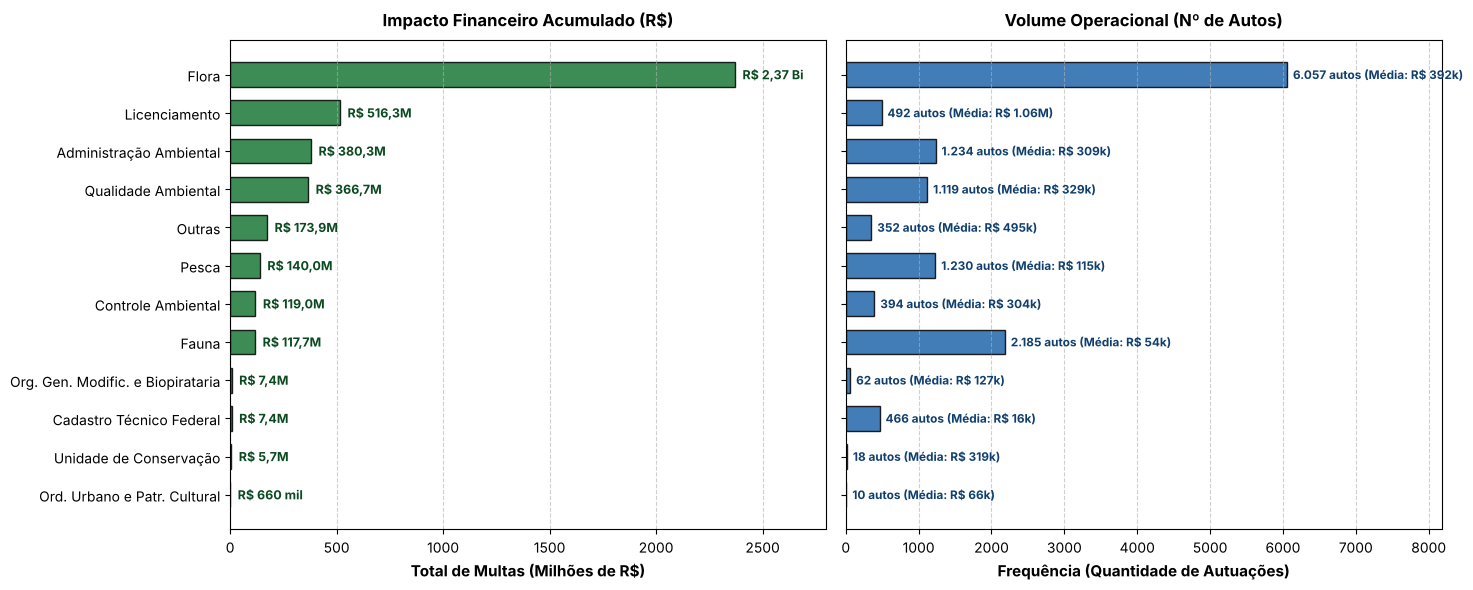

In [21]:
query9 = """
SELECT t.tipo_infracao, 
       COUNT(a.num_auto_infracao) AS total_autuacoes, 
       ROUND(COUNT(a.num_auto_infracao) * 100.0 / (SELECT COUNT(*) FROM Auto_Infracao), 2) AS pct_autuacoes, 
       ROUND(SUM(a.valor_multa), 2) AS valor_total_multas, 
       ROUND(SUM(a.valor_multa) * 100.0 / (SELECT SUM(valor_multa) FROM Auto_Infracao), 2) AS pct_valor_multas, 
       ROUND(AVG(a.valor_multa), 2) AS valor_medio_multa
FROM Auto_Infracao a
JOIN Tipo_Infracao t ON a.id_tipo = t.id_tipo
GROUP BY t.tipo_infracao
ORDER BY valor_total_multas DESC;
"""

df_q9 = fetch(query9, conn)
display(df_q9)

# Visualização Comparativa Multidimensional: Impacto Financeiro vs. Frequência (Volume de Autos)
df_sorted = df_q9.iloc[::-1].reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

c_financeiro = '#1b7837'  # verde floresta (impacto financeiro)
c_frequencia = '#2166ac'  # azul cobalto (volume operacional)

# 1. Painel Esquerdo: Impacto Financeiro Acumulado
bars1 = ax1.barh(df_sorted['tipo_infracao'], df_sorted['valor_total_multas'] / 1e6, 
                 color=c_financeiro, edgecolor='black', alpha=0.85, height=0.65)
ax1.set_xlabel('Total de Multas (Milhões de R$)', fontsize=11, fontweight='bold')
ax1.set_title('Impacto Financeiro Acumulado (R$)', fontsize=12, fontweight='bold', pad=10)
ax1.grid(axis='x', linestyle='--', alpha=0.6)

for bar, val in zip(bars1, df_sorted['valor_total_multas'] / 1e6):
    if val >= 1000.0:
        txt = f'R$ {val/1000:,.2f} Bi'.replace(',', 'X').replace('.', ',').replace('X', '.')
    elif val >= 1.0:
        txt = f'R$ {val:,.1f}M'.replace(',', 'X').replace('.', ',').replace('X', '.')
    else:
        txt = f'R$ {val*1000:,.0f} mil'.replace(',', '.')
    ax1.text(val + 35, bar.get_y() + bar.get_height()/2, txt, 
             va='center', ha='left', fontsize=9, fontweight='bold', color='#0b4a20')
ax1.set_xlim(0, max(df_sorted['valor_total_multas'] / 1e6) * 1.18)

# 2. Painel Direito: Frequência / Volume Operacional com Valor Médio
bars2 = ax2.barh(df_sorted['tipo_infracao'], df_sorted['total_autuacoes'], 
                 color=c_frequencia, edgecolor='black', alpha=0.85, height=0.65)
ax2.set_xlabel('Frequência (Quantidade de Autuações)', fontsize=11, fontweight='bold')
ax2.set_title('Volume Operacional (Nº de Autos)', fontsize=12, fontweight='bold', pad=10)
ax2.grid(axis='x', linestyle='--', alpha=0.6)

for bar, qtd, avg in zip(bars2, df_sorted['total_autuacoes'], df_sorted['valor_medio_multa']):
    if avg >= 1e6:
        avg_str = f'R$ {avg/1e6:.2f}M'.replace('.', ',')
    elif avg >= 1e3:
        avg_str = f'R$ {avg/1e3:.0f}k'
    else:
        avg_str = f'R$ {avg:.0f}'
    txt = f'{qtd:,d} autos (Média: {avg_str})'.replace(',', '.')
    ax2.text(qtd + 80, bar.get_y() + bar.get_height()/2, txt, 
             va='center', ha='left', fontsize=8.5, fontweight='bold', color='#103f6e')
ax2.set_xlim(0, max(df_sorted['total_autuacoes']) * 1.35)

#plt.suptitle('Comportamento Multidimensional por Macro-Tipo de Infração Ambiental (IBAMA 2026)\nAssimetria entre Impacto Financeiro (R$) e Volume Operacional de Autuações', 
#             fontsize=13, fontweight='bold', y=1.02)

os.makedirs('graficos', exist_ok=True)
plt.savefig('graficos/consulta_9_macro_infracoes.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

**Analisando os resultados**: A consulta evidencia uma forte **assimetria entre o volume operacional e o impacto financeiro das infrações**. A categoria Flora lidera em ambas as frentes, absorvendo 44,47% das autuações e 56,37% do valor total aplicado no país. O maior contraste, contudo, reside na comparação entre Licenciamento e Fauna: enquanto o Licenciamento responde por apenas 3,61% dos autos, mas concentra
12,28% do montante devido ao seu perfil corporativo de altíssima gravidade (média de **R\$ 1,06 milhão** por auto), a Fauna mobiliza 16,04% das operações de campo (segunda maior categoria), mas representa apenas 2,80% do valor financeiro, fruto de um ticket médio de apenas R\$ 54,4 mil por autuação.

### 6.4.2 Consulta 10
**Descrição:** Agregação sobre a junção de `Auto_Infracao` e `Municipio` para totalizar a quantidade de infrações lavradas e o valor acumulado de multas em 2026 agrupados por Unidade Federativa (UF), destacando os 10 estados com maior passivo ambiental e comprovando a liderança do Pará com cerca de 38% do volume nacional (Investigação: Concentração geográfica por UF). Inclui visualização comparativa em painel duplo por estado e mapeamento geoespacial de dispersão de coordenadas (latitude vs. longitude).

,uf,total_autuacoes,pct_autuacoes_nacional,valor_total_multas,pct_valor_nacional,valor_medio_multa
0,PA,2150,15.79,1.603235e+09,38.12,748475.62
1,MT,777,5.71,5.202327e+08,12.37,670402.93
2,RO,1005,7.38,4.427772e+08,10.53,442777.20
3,AM,705,5.18,3.382632e+08,8.04,481170.99
4,MS,189,1.39,1.637168e+08,3.89,866226.26
5,CE,458,3.36,1.299318e+08,3.09,283693.94
6,PR,673,4.94,1.259194e+08,2.99,189923.62
7,SC,684,5.02,1.006693e+08,2.39,148261.06
8,MA,374,2.75,9.433748e+07,2.24,252915.49
9,AC,590,4.33,6.973815e+07,1.66,118804.34


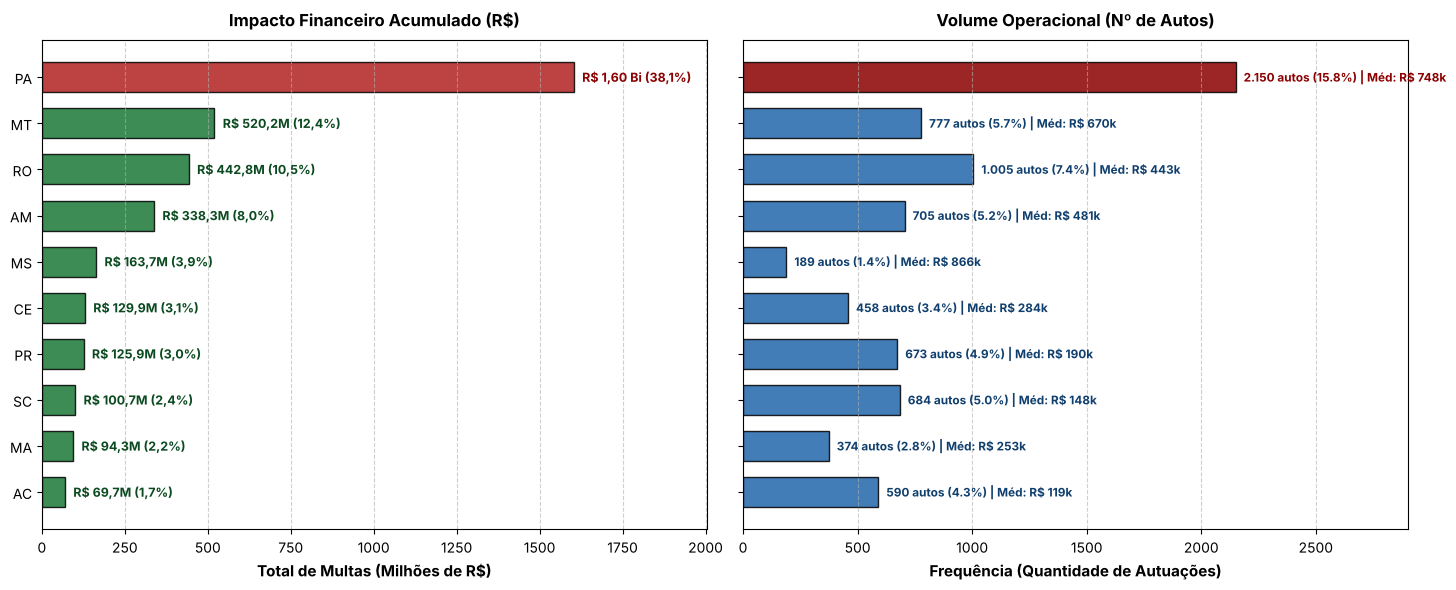

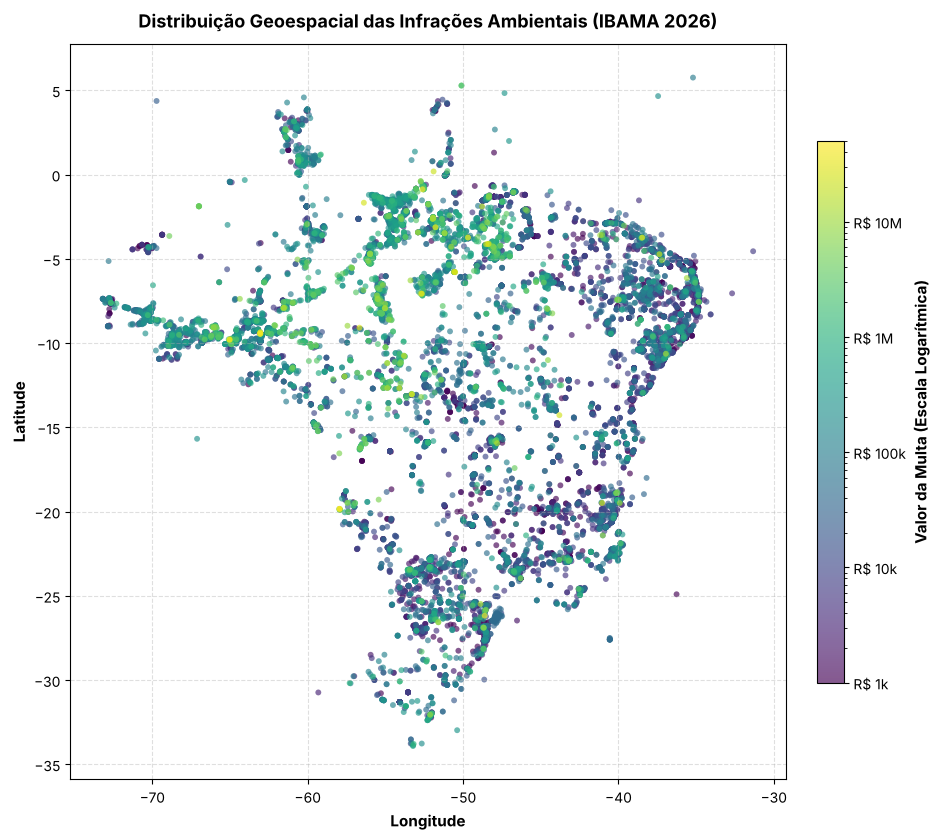

In [22]:
query10 = """
SELECT m.uf, 
       COUNT(a.num_auto_infracao) AS total_autuacoes, 
       ROUND(COUNT(a.num_auto_infracao) * 100.0 / (SELECT COUNT(*) FROM Auto_Infracao), 2) AS pct_autuacoes_nacional, 
       ROUND(SUM(a.valor_multa), 2) AS valor_total_multas,
       ROUND(SUM(a.valor_multa) * 100.0 / (SELECT SUM(valor_multa) FROM Auto_Infracao), 2) AS pct_valor_nacional,
       ROUND(AVG(a.valor_multa), 2) AS valor_medio_multa
FROM Auto_Infracao a
JOIN Municipio m ON a.cod_municipio = m.cod_municipio
GROUP BY m.uf
ORDER BY valor_total_multas DESC
LIMIT 10;
"""

df_q10 = fetch(query10, conn)
display(df_q10)

os.makedirs('graficos', exist_ok=True)

# 1. Visualização Comparativa Multidimensional: Impacto Financeiro vs. Frequência Operacional por UF
df_sorted = df_q10.iloc[::-1].reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

colors_fin = ['firebrick' if uf == 'PA' else '#1b7837' for uf in df_sorted['uf']]
colors_freq = ['darkred' if uf == 'PA' else '#2166ac' for uf in df_sorted['uf']]

# Painel Esquerdo: Impacto Financeiro Acumulado (Destaque do Pará ~38%)
bars1 = ax1.barh(df_sorted['uf'], df_sorted['valor_total_multas'] / 1e6, 
                 color=colors_fin, edgecolor='black', alpha=0.85, height=0.65)
ax1.set_xlabel('Total de Multas (Milhões de R$)', fontsize=11, fontweight='bold')
ax1.set_title('Impacto Financeiro Acumulado (R$)', fontsize=12, fontweight='bold', pad=10)
ax1.grid(axis='x', linestyle='--', alpha=0.6)

for bar, val, pct in zip(bars1, df_sorted['valor_total_multas'] / 1e6, df_sorted['pct_valor_nacional']):
    if val >= 1000.0:
        txt = f'R$ {val/1000:,.2f} Bi ({pct:.1f}%)'.replace(',', 'X').replace('.', ',').replace('X', '.')
    else:
        txt = f'R$ {val:,.1f}M ({pct:.1f}%)'.replace(',', 'X').replace('.', ',').replace('X', '.')
    ax1.text(val + 25, bar.get_y() + bar.get_height()/2, txt, 
             va='center', ha='left', fontsize=9, fontweight='bold', 
             color='#8b0000' if bar.get_facecolor()[:3] == (178/255, 34/255, 34/255) else '#0b4a20')
ax1.set_xlim(0, max(df_sorted['valor_total_multas'] / 1e6) * 1.25)

# Painel Direito: Frequência Operacional com Ticket Médio
bars2 = ax2.barh(df_sorted['uf'], df_sorted['total_autuacoes'], 
                 color=colors_freq, edgecolor='black', alpha=0.85, height=0.65)
ax2.set_xlabel('Frequência (Quantidade de Autuações)', fontsize=11, fontweight='bold')
ax2.set_title('Volume Operacional (Nº de Autos)', fontsize=12, fontweight='bold', pad=10)
ax2.grid(axis='x', linestyle='--', alpha=0.6)

for bar, qtd, avg, pct in zip(bars2, df_sorted['total_autuacoes'], df_sorted['valor_medio_multa'], df_sorted['pct_autuacoes_nacional']):
    if avg >= 1e6:
        avg_str = f'R$ {avg/1e6:.2f}M'.replace('.', ',')
    elif avg >= 1e3:
        avg_str = f'R$ {avg/1e3:.0f}k'
    else:
        avg_str = f'R$ {avg:.0f}'
    txt = f'{qtd:,d} autos ({pct:.1f}%) | Méd: {avg_str}'.replace(',', '.')
    ax2.text(qtd + 35, bar.get_y() + bar.get_height()/2, txt, 
             va='center', ha='left', fontsize=8.5, fontweight='bold', 
             color='#8b0000' if bar.get_facecolor()[:3] == (139/255, 0, 0) else '#103f6e')
ax2.set_xlim(0, max(df_sorted['total_autuacoes']) * 1.35)

#plt.suptitle('Top 10 Estados com Maior Volume de Multas Ambientais Aplicadas em 2026\nComparativo Multidimensional: Impacto Financeiro (R$) vs. Frequência Operacional (Autos)', 
#             fontsize=13, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('graficos/consulta_10_multas_por_uf.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Mapeamento Geoespacial Complementar: Dispersão de Coordenadas (Latitude vs. Longitude)
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter

query_geo = """
SELECT a.latitude, a.longitude, a.valor_multa, a.bioma, m.uf
FROM Auto_Infracao a
JOIN Municipio m ON a.cod_municipio = m.cod_municipio
WHERE a.latitude IS NOT NULL AND a.longitude IS NOT NULL
  AND a.latitude BETWEEN -35 AND 6 AND a.longitude BETWEEN -75 AND -30
  AND a.valor_multa > 0
ORDER BY a.valor_multa ASC;
"""
df_geo = fetch(query_geo, conn)

fig, ax = plt.subplots(figsize=(9.5, 8.5))
sc = ax.scatter(
    df_geo['longitude'], 
    df_geo['latitude'], 
    c=df_geo['valor_multa'], 
    cmap='viridis', 
    norm=LogNorm(vmin=1000, vmax=50000000),
    alpha=0.65, 
    s=18, 
    edgecolors='none'
)

def format_reais(val, pos):
    if val >= 1e6:
        return f'R$ {val/1e6:.0f}M'
    elif val >= 1e3:
        return f'R$ {val/1e3:.0f}k'
    else:
        return f'R$ {val:.0f}'

cbar = plt.colorbar(sc, ax=ax, fraction=0.035, pad=0.04, format=FuncFormatter(format_reais))
cbar.set_label('Valor da Multa (Escala Logarítmica)', fontsize=11, fontweight='bold')

ax.set_xlabel('Longitude', fontsize=11, fontweight='bold')
ax.set_ylabel('Latitude', fontsize=11, fontweight='bold')
ax.set_title('Distribuição Geoespacial das Infrações Ambientais (IBAMA 2026)', fontsize=13, fontweight='bold', pad=12)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('graficos/analise_dispersao_geoespacial.png', dpi=300, bbox_inches='tight')
plt.show()

**Analisando os resultados:** A distribuição geográfica revela uma hiperconcentração territorial do passivo ambiental brasileiro. O estado do **Pará (PA)** destaca-se isoladamente como o epicentro da fiscalização, respondendo por **15,79%** das autuações e concentrando expressivos **38,12%** de todo o montante financeiro nacional (**R\$ 1,60 bilhão**, com média de **R\$ 748,5 mil** por auto). Em conjunto, os quatro principais estados da Amazônia Legal (**PA, MT, RO e AM**) concentram **69,06%** do passivo financeiro do país, proporção que atinge **72,96%** ao incluir MA e AC. Destaca-se também a singularidade do **Mato Grosso do Sul (MS)**, que, apesar de responder por apenas **1,39%** das autuações (189 autos), registra **a maior penalidade média do Top 10 (R\$ 866,2 mil por auto)**, refletindo ações de grande porte no Pantanal e Cerrado em grandes propriedades rurais. Em contraste, estados da região Sul como **Paraná (PR)** e **Santa Catarina (SC)** exibem volumes operacionais expressivos (~5% dos autos cada), mas geram participações financeiras modestas (2,99% e 2,39%), com tickets médios inferiores a R\$ 190 mil decorrentes da fiscalização de pequenos ilícitos e propriedades fragmentadas no bioma Mata Atlântica.

# 7. Autoavaliação dos membros

Abaixo são detalhadas as contribuições individuais desenvolvidas pelos membros da equipe ao longo de todas as etapas de planejamento, modelagem, implementação e análise analítica do Trabalho Prático 2:

* **Evandro Araújo Furlaneto Delgado (2025018830):**
  * Reformulação da consulta 1 (Seção 6.1.1), que passou a contar, por bioma, as multas simples de valor igual ou superior a R$ 1.000.000,00.
  * Análises e realização das consultas 1 e 2.
---
* **Letícia Schmidt Tolentino Santos (2025014168):**
  * Inclusão, na consulta 10, da subconsulta de percentual nacional por UF, que fundamenta a participação de cerca de 38% do Pará citada na Consulta 6.
  * Análises e realização das consultas 6 e 7, além do refinamento breve das análises das consultas 1 e 2.
  * Padronização do Jupyter Notebook em revisão final.
  * Identificação de entidades, relacionamentos, incluindo suas respectivas instâncias, e investigações previstas na proposta da Entrega 1.
---
* **Victor Daniel Barbosa Thomé (2026303953):**
  * Criação da primeira versão do notebook no google colab, assim como primeiras análises sobre o banco de dados. 
  * Análises e realização das consultas 3 e 4.
  * Definição de algumas entidades e atributos.
---
* **Vitória Medeiros Carrera de Oliveira (2019027245):**
  * Análise da qualidade dos dados do arquivo de 2026 (valores nulos por coluna, autos repetidos e inconsistências de CPF/CNPJ e de nomes de municípios) e revisão da proposta e do modelo em relação aos requisitos do enunciado.
  * Correção da carga dos dados na Seção 3: padronização do CPF/CNPJ dos infratores, escolha da versão *Lavrado* nos autos repetidos, construção da tabela `Autuado_Em` a partir dos autos carregados e atualização das contagens de instâncias.
  * Elaboração do diagrama ER e correção da cardinalidade do relacionamento RECEBE.
  * Responsável pelas consultas 5 e 8: revisão das consultas, conferência dos resultados no banco e redação das análises.
  * Desenvolvimento da aplicação Streamlit (parte extra), com filtros interativos, visão geral, mapa dos autos, análise de infratores e operações e execução das 10 consultas do relatório.
---
* **Yuri Florentino Kosfeld (2022038503):**
  * Estruturação da versão inicial do notebook segundo o template: processamento do CSV e carga no SQLite, DDL das seis tabelas, diagrama relacional e formulação das consultas 9 e 10.
  * Criação do repositório e do README com o fluxo de trabalho no Git (branches, pull requests e revisão), além da revisão e integração das contribuições dos membros.
  * Geração dos gráficos em alta resolução na pasta graficos/ para os slides, incluindo o mapeamento geoespacial dos autos.
  * Inclusão de subconsultas de percentual e reformulação dos gráficos das consultas 9 e 10, com a redação das respectivas análises.
  * Definição do tema do trabalho na Entrega 1.